## 1. 数据处理和特征生成

在真正计算市场之间的距离之前，先要回答一个更基础的问题：到底用什么来描述“今天的市场”？如果只拿某一天的几十个原始变量做比较，得到的更像一张市场快照。但我们显然更关心的是一段时间里的状态演化：市场是在持续上涨还是刚刚反弹，波动率是在扩张还是收缩，某类宏观特征是长期处于高位还是刚刚发生变化。两个时点的数值可以很接近，但它们走到这里的路径可能完全不同。

因此这一节先处理原始数据，再把单日特征扩展成能够描述水平、变化、趋势和风险状态的一组滚动特征。后面的Optimal Transport（以下简称OT）就建立在这些市场状态之上。

数据按时间顺序处理，不做随机打乱。先检查各类特征在训练期的覆盖情况，再确定真正进入研究的有效样本区间。

In [134]:
import numpy as np
import pandas as pd

df = pd.read_csv("archive/train.csv")

n = len(df)

train_end = int(n * 0.60)
val_end = int(n * 0.80)

train = df.iloc[:train_end].copy()
val = df.iloc[train_end:val_end].copy()
test = df.iloc[val_end:].copy()

print(len(train), len(val), len(test))

5428 1810 1810


In [135]:
CONT_GROUPS = ["M", "V", "S", "I", "E", "P"]
D_GROUP = "D"

group_columns = {
    group: [
        col for col in df.columns
        if col.startswith(group)
        and col[1:].isdigit()
    ]
    for group in CONT_GROUPS + [D_GROUP]
}

for group, cols in group_columns.items():
    print(group, len(cols), cols)

coverage = pd.DataFrame({
    group : {
        "列数": len(cols),
        "训练期缺失比例": train[cols].isna().mean().mean() if cols else np.nan,
        "最早有值的位置": min(
            (train[col].first_valid_index()
            for col in cols 
            if train[col].first_valid_index() is not None
            ),
            default=np.nan
        ),
        }
        for group, cols in group_columns.items()
}).T

display(coverage)

M 18 ['M1', 'M10', 'M11', 'M12', 'M13', 'M14', 'M15', 'M16', 'M17', 'M18', 'M2', 'M3', 'M4', 'M5', 'M6', 'M7', 'M8', 'M9']
V 13 ['V1', 'V10', 'V11', 'V12', 'V13', 'V2', 'V3', 'V4', 'V5', 'V6', 'V7', 'V8', 'V9']
S 12 ['S1', 'S10', 'S11', 'S12', 'S2', 'S3', 'S4', 'S5', 'S6', 'S7', 'S8', 'S9']
I 9 ['I1', 'I2', 'I3', 'I4', 'I5', 'I6', 'I7', 'I8', 'I9']
E 20 ['E1', 'E10', 'E11', 'E12', 'E13', 'E14', 'E15', 'E16', 'E17', 'E18', 'E19', 'E2', 'E20', 'E3', 'E4', 'E5', 'E6', 'E7', 'E8', 'E9']
P 13 ['P1', 'P10', 'P11', 'P12', 'P13', 'P2', 'P3', 'P4', 'P5', 'P6', 'P7', 'P8', 'P9']
D 9 ['D1', 'D2', 'D3', 'D4', 'D5', 'D6', 'D7', 'D8', 'D9']


,列数,训练期缺失比例,最早有值的位置
M,18.0,0.418724,1006.0
V,13.0,0.319554,1006.0
S,12.0,0.330585,1006.0
I,9.0,0.185335,1006.0
E,20.0,0.238854,1006.0
P,13.0,0.210986,1006.0
D,9.0,0.000000,0.0


原始数据中，M、V、S、I、E、P 是六组连续变量，D则更像一组离散的市场状态标签。
我们在这里先做两个简单筛选。连续变量只保留训练期覆盖率不低于80%的列；D类变量如果在训练期完全重复，只保留其中一列。前期有一段数据存在大范围缺失，因此在检查覆盖情况后，将前1006行排除在正式样本之外，再从有效区间按时间顺序划分training、validation和test。
对OT来说，真正重要的不是某一列特征本身，而是这些变量能不能共同还原出一段市场环境。因此我没有直接把所有原始变量塞进距离计算，而是把它们压缩成几组更容易解释的“状态变量”：
- 收益、趋势与波动：18维，包括多尺度动量、波动率、上涨日比例、趋势强度、回撤、上下行风险以及趋势拟合程度；
- 六组连续特征：18维，每一组分别提取当前水平、5日变化和20日变化；
- D类状态：8维，记录各离散状态在最近20日内出现的频率；
- 补充趋势与风险特征：9维，包括趋势效率、动量加速度、动量一致性、距离高低点以及波动率本身的变化等。

最终得到53个市场特征。
这里有意保留不同时间尺度。比如“过去20天涨了多少”和“过去5天相对于过去20天是否突然加速”描述的是两件不同的事；同样，市场当前波动率很高，与“波动率正在迅速上升”也不是同一种状态。
所有涉及缺失值填补和标准化的参数都只在training period上估计，再原样应用到validation和test。这样后面的距离计算不会提前看到未来数据。
机器学习部分则不使用这套53维OT状态特征，这些状态特征只为OT判断市场距离服务。第四节我们继续使用前面筛选后的原始变量。两部分解决的问题不同：OT需要一个适合比较“市场形状”的状态空间，而机器学习更适合直接从原始信息中学习预测关系。

In [136]:
coverage_start = 1006
#筛选后的训练集

new_train_end = coverage_start + int(
    (len(df) - coverage_start) * 0.60
)

new_val_end = coverage_start + int(
    (len(df) - coverage_start) * 0.80
)

train = df.iloc[coverage_start:new_train_end].copy()
val = df.iloc[new_train_end:new_val_end].copy()
test = df.iloc[new_val_end:].copy()
#选取缺失值不超过80%的列
MIN_COVERAGE = 0.8
selected_continuous_columns = {}

for group in CONT_GROUPS:
    cols = group_columns[group]
    coverage = train[cols].notna().mean()
    selected_cols = coverage[
        coverage >= MIN_COVERAGE
    ].index.tolist()

    selected_continuous_columns[group] = selected_cols

for group, cols in selected_continuous_columns.items():
    print(
        group,
        f"原始列数={len(group_columns[group])}",
        f"保留列数={len(cols)}"
    )

M 原始列数=18 保留列数=11
V 原始列数=13 保留列数=11
S 原始列数=12 保留列数=9
I 原始列数=9 保留列数=9
E 原始列数=20 保留列数=19
P 原始列数=13 保留列数=13


In [137]:
#处理离散类型D
d_cols = group_columns["D"]
d_train = train[d_cols]

duplicate_pairs = []

for i, col1 in enumerate(d_cols):
    for col2 in d_cols[i+1:]:
        if train[col1].equals(train[col2]):
            duplicate_pairs.append((col1,col2))

duplicate_pairs

[('D1', 'D2')]

In [138]:
d_cols_clean = d_cols.copy()

for col1, col2 in duplicate_pairs:
    if col2 in d_cols_clean:
        d_cols_clean.remove(col2)

print("原D列:", d_cols)
print("去重后:", d_cols_clean)

原D列: ['D1', 'D2', 'D3', 'D4', 'D5', 'D6', 'D7', 'D8', 'D9']
去重后: ['D1', 'D3', 'D4', 'D5', 'D6', 'D7', 'D8', 'D9']


In [139]:
# 第一节构造市场状态窗口；与基础策略的60日趋势信号独立。
WINDOW = 40

接下来把这些单日状态连成一段40个交易日的市场窗口。
这是整个OT设计里很关键的一步。我不希望算法只判断“两个市场的平均状态像不像”，还希望它能分辨状态是怎样演化过来的。因此，对于决策日\(t\)，实际使用的市场窗口为[t-40, t)。
也就是说窗口最后一天是\(t-1\)，当天尚未实现的收益不会进入状态描述。
每个窗口中的每一天都是一个 53 维市场状态点。除此之外，我再加入一个从0到5递增的窗口内相对时间坐标，因此最终 OT 使用的是54维状态。
这个时间坐标不是“这个历史样本离今天有多久”，而是在告诉运输问题：窗口前半段的状态最好和另一个窗口的前半段匹配，后半段也尽量和后半段匹配。 如果完全不加入时间信息，OT只关心两组点是否相似，可能把一段“先跌后涨”的市场和“先涨后跌”的市场认为非常接近。
综合来讲，可以把它理解成：53个特征负责描述市场当时“长什么样”，最后那个时间坐标负责保留它“按什么顺序走到了这里”。
最长的滚动特征需要60日历史，因此早期历史不足的窗口自然保留为缺失，并不会参与后续近邻检索。时间维度乘以5是为了让路径顺序在距离中拥有足够的影响，但又不至于盖过市场特征本身。它是状态空间的一部分。

In [140]:
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler

TIME_WEIGHT = 5.0


def build_market_features(data, state_index, fit_index):
    """构造相同的滚动市场特征；填补和标准化只拟合fit_index对应的训练期。"""
    training_data = data.loc[fit_index]
    state_returns = data.loc[state_index, 'forward_returns']

    # 行s的特征使用截至s的数据；决策t取[t-WINDOW,t)，最后一行为t-1。防止未来数据泄露
    # 此处不再shift(1)，否则会额外滞后一天。

    # 1. 收益、趋势和波动特征：18维
    rolling_features = pd.DataFrame(index=state_index)
    state_log_returns = np.log1p(state_returns)

    # 多尺度动量：累计对数收益；正值表示上涨，负值表示下跌。
    for span in [5,10,20,40,60]:
        rolling_features[f'momentum_{span}'] = state_log_returns.rolling(span, min_periods=span).sum()

    # 年化波动率：日收益标准差乘sqrt(252)，越大表示波动越强。
    for span in [5,20,60]:
        rolling_features[f'volatility_{span}'] = (
            state_returns.rolling(span, min_periods=span).std() * np.sqrt(252)
        )

    # 上涨日比例：过去20日正收益的比例，描述上涨的持续程度。
    rolling_features['up_ratio_20'] = (
        (state_returns > 0).astype(float).where(state_returns.notna()).rolling(20, min_periods=20).mean()
    )

    # 趋势强度：20日动量相对于同期波动；有方向，绝对值描述强度。
    rolling_features['trend_strength_20'] = (
        rolling_features.momentum_20 / (state_returns.rolling(20, min_periods=20).std().clip(lower=1e-08) * np.sqrt(20))
    )

    # 短期/长期波动比：大于1表示短期波动比长期波动更强。
    rolling_features['vol_ratio_5_20'] = (
        rolling_features.volatility_5 / rolling_features.volatility_20.clip(lower=1e-08)
    )
    rolling_features['vol_ratio_20_60'] = (
        rolling_features.volatility_20 / rolling_features.volatility_60.clip(lower=1e-08)
    )

    # 由市场收益构造净值；用于计算相对高点、低点的位置。
    market_nav = (1 + state_returns.fillna(0)).cumprod()
    # 60日回撤：当前净值/窗口最高净值-1；0表示高点，-0.1表示低于高点10%。
    rolling_features['drawdown_60'] = market_nav / market_nav.rolling(60, min_periods=60).max() - 1

    # 下行波动：负收益平方均值开根再年化；正收益按0计，分母为全部20日。
    rolling_features['downside_vol_20'] = (
        np.sqrt(state_returns.clip(upper=0).pow(2).rolling(20, min_periods=20).mean()) * np.sqrt(252)
    )
    market_log_nav = np.log1p(state_returns).fillna(0).cumsum()

    # 直线斜率：对数净值拟合斜率乘窗口长度；正值向上，负值向下。
    def rolling_slope(s,span):
        x = np.arange(span, dtype=float)
        x -= x.mean()
        den = (x * x).sum()
        return s.rolling(span, min_periods=span).apply(lambda y: np.dot(y - y.mean(), x) / den, raw=True) * span

    # 趋势R²：直线拟合程度，接近1表示路径平稳；本身不区分涨跌。
    def rolling_trend_r2(s,span):
        x = np.arange(span, dtype=float)
        return s.rolling(span, min_periods=span).apply(lambda y: 0.0 if np.std(y) < 1e-12 else np.corrcoef(x, y)[0, 1] ** 2, raw=True)
    for span in [20,40]:
        rolling_features[f'slope_{span}'] = rolling_slope(market_log_nav, span)
        rolling_features[f'trend_r2_{span}'] = rolling_trend_r2(market_log_nav, span)

    # 2. 六组原始连续特征：每组水平、5日变化、20日变化，共18维。
    # 填补和标准化只在训练集拟合；组内中位数减少极端值影响。
    for group in CONT_GROUPS:
        columns = selected_continuous_columns[group]
        group_imputer = SimpleImputer(strategy='median')
        group_scaler = StandardScaler()
        train_values = group_imputer.fit_transform(training_data[columns])
        group_scaler.fit(train_values)
        group_array = group_scaler.transform(group_imputer.transform(data.loc[state_index, columns]))
        group_values = pd.DataFrame(group_array, index=state_index, columns=columns)
        # 当前组水平：组内标准化特征的中位数。
        rolling_features[f'{group}_level'] = group_values.median(axis=1)
        # 5日变化：先算每列变化，再取组内中位数。
        rolling_features[f'{group}_change_5'] = (group_values - group_values.shift(5)).median(axis=1)
        # 20日变化：描述较长期的组状态变化。
        rolling_features[f'{group}_change_20'] = (group_values - group_values.shift(20)).median(axis=1)

    # 3. D类状态：最近20日非零状态出现频率；当前去重后8列，共8维。
    # 0表示从未出现，1表示每天出现；缺失值用训练集众数填补。
    d_imputer = SimpleImputer(strategy='most_frequent')
    d_imputer.fit(training_data[d_cols_clean])
    d_values = d_imputer.transform(data.loc[state_index, d_cols_clean])
    d_binary = pd.DataFrame(d_values, index=state_index, columns=d_cols_clean).ne(0).astype(float)
    for column in d_cols_clean:
        rolling_features[f'{column}_freq20'] = d_binary[column].rolling(20, min_periods=20).mean()

    # 4. 新增9个非重复特征。
    # 趋势效率：累计收益/收益绝对值之和；接近±1表示单向，接近0表示震荡。
    for span in [20, 40]:
        rolling_features[f'trend_efficiency_{span}'] = (
            state_returns.rolling(span).sum() / state_returns.abs().rolling(span).sum().clip(lower=1e-08)
        )

    # 动量加速度：最近5日动量减20日平均速度折算到5日；正值表示改善。
    rolling_features['momentum_acceleration'] = (
        rolling_features['momentum_5'] - rolling_features['momentum_20'] * (5 / 20)
    )

    # 动量一致性：5日与40日收益方向，在过去20日内相同的比例。
    short_sign = np.sign(state_returns.rolling(5).sum())
    long_sign = np.sign(state_returns.rolling(40).sum())
    consistent = short_sign.eq(long_sign).astype(float).where(short_sign.notna() & long_sign.notna())
    rolling_features['momentum_consistency'] = consistent.rolling(20, min_periods=20).mean()

    # 距20日高点：0表示在高点，负值表示低于高点；60日版本已有drawdown_60。
    rolling_features['distance_to_high_20'] = (
        market_nav / market_nav.rolling(20, min_periods=20).max() - 1
    )

    # 距20/60日低点：0表示在低点，正值表示从低点上涨的幅度。
    for span in [20, 60]:
        rolling_features[f'distance_to_low_{span}'] = (
            market_nav / market_nav.rolling(span, min_periods=span).min() - 1
        )

    # 上行波动：与下行波动同算法，仅保留正收益。
    upside_vol_20 = (
        np.sqrt(state_returns.clip(lower=0).pow(2).rolling(20, min_periods=20).mean()) * np.sqrt(252)
    )

    # 下行/上行波动比：大于1表示下跌波动更强。
    rolling_features['downside_upside_ratio'] = (
        rolling_features['downside_vol_20'] / upside_vol_20.clip(lower=1e-08)
    )

    # 波动率的波动：20日波动率在最近20日内的标准差，衡量风险水平的稳定性。
    rolling_features['vol_of_vol_20'] = (
        state_returns.rolling(20, min_periods=20).std().rolling(20, min_periods=20).std()
    )

    # 5. 对全部市场特征统一标准化：仅用完整的训练期行拟合。
    # 滚动历史不足的行保留NaN，不用0伪造市场状态。
    rolling_features = rolling_features.replace([np.inf, -np.inf], np.nan)
    complete_rows = rolling_features.notna().all(axis=1)
    complete_train_index = training_data.index[complete_rows.loc[training_data.index].to_numpy()]
    state_scaler = StandardScaler().fit(rolling_features.loc[complete_train_index])
    X_distance = pd.DataFrame(np.nan, index=state_index, columns=rolling_features.columns)
    X_distance.loc[complete_rows] = state_scaler.transform(rolling_features.loc[complete_rows])

    return rolling_features, X_distance, state_scaler


def build_market_cache(X_distance):
    """缓存[t-WINDOW,t)窗口，并加入相对时间坐标；不包含决策日收益。"""
    # 6. 缓存市场窗口，追加一个不再标准化的相对时间坐标。
    distance_positions = {index: pos for pos, index in enumerate(X_distance.index)}
    values = X_distance.to_numpy(dtype=float)
    windows = np.lib.stride_tricks.sliding_window_view(values, WINDOW, axis=0)
    # (窗口数量, WINDOW个交易日, 市场特征数量)；去掉末尾之后的决策窗口。
    windows = windows[:-1].transpose(0, 2, 1)
    state_dimension = values.shape[1] + 1
    state_windows = np.empty((len(windows), WINDOW, state_dimension), dtype=float)
    state_windows[:, :, :-1] = windows
    # 每个窗口从0到5；跨窗口把早期日与晚期日匹配，会增加运输成本。
    # 这是窗口内相对时间，不是历史样本距今的远近。
    state_windows[:, :, -1] = TIME_WEIGHT * np.linspace(0, 1, WINDOW)
    window_cache = {'rolling_state': state_windows}
    valid_state_indices = X_distance.index[WINDOW:][np.isfinite(state_windows).all(axis=(1, 2))]
    return distance_positions, window_cache, valid_state_indices, state_dimension


# 本节先构造训练期与验证期；第五节用同一函数追加测试期。
state_index = train.index.union(val.index)
rolling_features, X_distance, state_scaler = build_market_features(df, state_index, train.index)
distance_positions, window_cache, valid_state_indices, state_dimension = build_market_cache(X_distance)
print(f"市场特征：{X_distance.shape[1]}维；加时间坐标：{state_dimension}维")
print(f"有效市场窗口：{len(valid_state_indices)}个；起点：{valid_state_indices[0]}")

市场特征：53维；加时间坐标：54维
有效市场窗口：6334个；起点：1105


## 2. Wasserstein距离与最优运输

第一节做完以后，每个40日窗口都可以看成一段由54维状态点组成的市场轨迹。接下来的问题就很直接了：给定今天之前的这40天，历史上哪些40天和它最像？
如果直接比较两个窗口的均值，会丢掉大量信息；如果把第1天硬和第1天比较、第2天硬和第2天比较，又会过于死板。这里采用二阶Wasserstein 距离，让两个窗口中的状态点自己寻找一组总成本最低的匹配。
直观地说，Optimal Transport问的是：要把一段市场状态“搬运”成另一段市场状态，最少需要付出多少代价？ 代价越小，两段市场就越相似。

设两个长度都为 $W$ 的市场窗口为
$$
X=\{x_1,\ldots,x_W\},\qquad
Y=\{y_1,\ldots,y_W\},
$$
其中每个 $(x_i,y_j)$ 都是一个 54 维市场状态。
由于每一天的权重相同，而且两个窗口长度一致，最优运输在这里可以写成一个一一匹配问题：
$$
W_2(X,Y)
=
\sqrt{
\min_{\pi}
\frac{1}{W}
\sum_{i=1}^{W}
\|x_i-y_{\pi(i)}\|_2^2
}.
$$
其中$\pi$是所有可能配对中的一个排列。换句话说，算法会尝试回答：窗口$X$中的每一天，应该和窗口$Y$中的哪一天配对，才能让总体状态差异最小？
这里使用平方欧氏距离作为运输成本，并通过Hungarian algorithm精确求解最优的一一配对。由于第一节已经额外加入了窗口内时间坐标，这个匹配虽然允许适度“错位”，但大幅跨越时间位置会额外付出成本，因此市场演化的先后顺序不会被完全打散。

In [141]:
from scipy.spatial.distance import cdist
from scipy.optimize import linear_sum_assignment

def wasserstein_distance_2(X, Y):
    if X.shape != Y.shape:
        raise ValueError("两个窗口的样本数和特征维数必须一致")

    #代价函数为，两个样本点之间的欧氏平方距离
    cost = cdist(X, Y, metric="sqeuclidean")
    #找到总成本最小的一一配对
    row_ind, col_ind = linear_sum_assignment(cost)
    
    #返回总代价
    return float(
        np.sqrt(cost[row_ind, col_ind].mean())
    )

正式计算时直接使用第一节缓存好的完整市场窗口：53个市场状态特征，加上1个相对时间坐标，一共54维。
所有特征在进入距离计算前已经按照训练期参数完成填补和标准化，因此不同量纲的变量不会因为数值大小不同而主导距离。最后再将 Wasserstein 距离除以
$$
\sqrt{54},
$$
相当于把距离按维度做一次归一化。这样以后即使调整状态空间的维度，距离尺度也更容易比较。

In [142]:
def market_distance_cached(decision_index_a, decision_index_b):
    pos_a = distance_positions[decision_index_a]
    pos_b = distance_positions[decision_index_b]
    if min(pos_a, pos_b) < WINDOW:
        raise ValueError("决策日之前没有完整的市场窗口")

    # 决策日pos使用pos-WINDOW到pos-1，不包含当天。
    window_a = window_cache["rolling_state"][pos_a - WINDOW]
    window_b = window_cache["rolling_state"][pos_b - WINDOW]
    if not (np.isfinite(window_a).all() and np.isfinite(window_b).all()):
        raise ValueError("市场窗口含有尚未生成的滚动特征")

    # 完整市场状态一起做精确OT，除以sqrt(维度数)归一化距离。
    return wasserstein_distance_2(window_a, window_b) / np.sqrt(state_dimension)

精确 OT 的问题是：它不便宜。
一个决策日可能有上千个历史候选窗口，如果每一个都先构造$40\times40$的成本矩阵，再做一次完整assignment，回测会非常慢。但我们的目标只是找到距离最近的20个历史窗口，并不需要精确知道所有历史时期的距离。
因此这里先给每个候选窗口算一个便宜得多的距离下界：
$$
W_2(X,Y)\ge
\sqrt{\|\mu_X-\mu_Y\|_2^2+
      \|\sigma_X-\sigma_Y\|_2^2}
$$
这个下界有一个很实用的性质：它可能低估真实Wasserstein 距离，但不会高估。
因此可以先按下界从小到大排列候选窗口，再逐个计算真正的OT距离，同时维护当前最好的20个近邻。一旦后面某个候选的理论下界已经大于当前第20名的真实距离，那么排在它之后的窗口也不可能进入前20，搜索可以直接停止。
也就是说，我们不是近似Wasserstein 距离，而只是用一个便宜的下界来判断：哪些昂贵的距离根本没有必要算。

In [143]:
window_means = {
    group: windows.mean(axis=1)
    for group, windows in window_cache.items()
}

window_stds = {
    group: windows.std(axis=1, ddof=0)
    for group, windows in window_cache.items()
}

设置近邻数量与两个温度参数。这里先定义通用检索函数；第三节生成策略收益标签后，才能对具体决策日检索、打分并配置仓位。

In [144]:
from scipy.special import softmax

K = 20                       # 相似历史市场状态数量
DISTANCE_TEMPERATURE = 1.0    # 距离转近邻权重的温度
SCORE_TEMPERATURE = 0.01      # 策略分数转权重的温度

到这里，我们已经可以完成这一节真正需要的任务：对于任意决策日$t$，从已经发生、并且后续收益已经完全实现的历史中，找出Wasserstein距离最近的$K=20$个市场窗口。
这里还有一个很容易忽略的时间约束。一个历史窗口即使和今天很像，如果它后面的20日策略收益在决策日$t$尚未完全发生，就不能拿来给今天打分。因此历史样本$s$必须满足：
$$
s+\text{WINDOW}+\text{HORIZON}\le t.
$$
这个限制确保近邻检索始终只使用在当时已经能够观察到的信息。

In [145]:
import heapq


def find_nearest_neighbors(decision_index, history_indices=None):
    # 第三节默认使用基础策略标签；第四节可以传入OOF标签索引。
    if history_indices is None:
        history_indices = valid_history_indices
    if decision_index not in valid_state_indices:
        raise ValueError("当前决策日没有完整、有效的市场状态")

    # 同时具备策略标签和完整市场窗口，排除滚动历史不足的日期。
    history = history_indices.intersection(valid_state_indices)
    # 保留原来的标签成熟与窗口间隔规则。
    history = history[history + HORIZON + WINDOW <= decision_index]
    if len(history) < K:
        raise ValueError("已成熟且市场状态有效的历史样本不足K个")

    current_window = distance_positions[decision_index] - WINDOW
    history_windows = np.array([distance_positions[s] - WINDOW for s in history])
    mean_diff = (window_means["rolling_state"][history_windows]
                 - window_means["rolling_state"][current_window])
    std_diff = (window_stds["rolling_state"][history_windows]
                - window_stds["rolling_state"][current_window])
    # 严格W2下界，使用与精确距离一致的维度归一化。
    lower_bounds = np.sqrt((mean_diff ** 2 + std_diff ** 2).sum(axis=1) / state_dimension)
    order = np.lexsort((history.to_numpy(), lower_bounds))
    best = []
    exact_count = 0
    for i in order:
        # 后续下界已比当前第K名更大，不可能改进结果。
        if len(best) == K and lower_bounds[i] > -best[0][0] + 1e-12:
            break
        history_index = int(history[i])
        distance = market_distance_cached(decision_index, history_index)
        exact_count += 1
        # 负距离让堆顶为最远近邻；并列时优先保留更早日期。
        item = (-distance, -history_index)
        if len(best) < K:
            heapq.heappush(best, item)
        elif item > best[0]:
            heapq.heapreplace(best, item)

    selected = sorted((-distance, -index) for distance, index in best)
    distances = pd.Series(
        [distance for distance, index in selected],
        index=[index for distance, index in selected], name="distance"
    )
    return distances, exact_count, len(history)

## 3. 策略配置

前两节解决了一个问题：历史上什么时候和现在最像？
但找到相似时期本身并不能赚钱。真正需要回答的是另一个问题：在这些“似曾相识”的市场环境之后，什么样的策略表现得更好？
为了让这个问题容易被理解，我先不使用复杂模型，而是设计三种风格非常不同的基础策略：趋势、均值回归和防守。它们不追求单独成为最强策略，而是刻意代表三种不同的市场观点。这样，当市场状态发生变化时，OT才真正有“选择”的空间。

三种基础策略及时间约定

在决策日$t$开始时，`forward_returns[t]`尚未实现。信号只使用截至$t-1$的收益，市场状态使用第一节构造的$[t-40,t)$特征窗口。

| 策略 | 信号（均不含当天收益） | 市场仓位 | 设计意图 |
|---|---|---|---|
| trend | 过去60日市场复利收益 | 动量>0时为1，否则为0 | 上涨时持仓，负趋势时持现金 |
| mean_reversion | 过去5日累计对数收益 / (20日对数收益标准差 × √5) | clip(0.5 − z/2, 0, 1) | 短期下跌加仓、短期上涨减仓 |
| defensive | 过去20日收益年化波动率 | min(0.3, 0.05 / 波动率) | 低市场暴露，高波动时进一步降仓 |

三个策略故意做得很不一样。
Trend相信趋势延续；Mean Reversion相信短期价格会向正常水平回归；Defensive则几乎不表达方向判断，只负责在风险较高的时候尽量少参与。
这正是后面OT需要的东西。如果三个策略每天做出的决定都差不多，那么再聪明的配置算法也没有太多发挥空间。
所有未投入市场的资金按当日无风险收益率计息。三种基础策略本身均不使用杠杆，仓位限制在$0$到$1$之间。
这三种是我们设计的基础策略，分别反映了不同市场状态时采取的最简单的交易策略。剩余资金按 `risk_free_rate` 计息。同时我们假定上一行的收益在下一决策时点已可观察。

单日毛收益为 $p_t r_t+(1-p_t)r_{f,t}$。交易成本按收益导致的持仓漂移后的实际调仓量计算，单边费率默认1bp；费用用调仓前净值计算。历史标签采用连续运行策略的净收益，不能在每个标签起点重新清仓。

In [146]:
#接合验证集和训练集
returns = pd.concat([
    train["forward_returns"],
    val["forward_returns"]
], axis=0)

#当天决策之用更早的收益
past_returns = returns.shift(1)

#转换为对数收益
past_log_returns = np.log1p(past_returns)

#1.趋势信号：过去60日的复利收益
momentum_60 = np.expm1(
    past_log_returns.rolling(window = 60, min_periods = 60).sum()
)

#2.均值回归信号：过去5日累计对数收益，除以估计的5日收益标准差
log_return_5 = (
    past_log_returns.rolling(window = 5, min_periods = 5).sum()
)

log_volatility_20 = (
    past_log_returns.rolling(window = 20, min_periods = 20).std()
)

z_score = log_return_5 / (
    log_volatility_20.clip(lower=1e-8) * np.sqrt(5)
)

#防守信号：过去20日的收益年化波动率
annual_volatility_20 = (
    past_returns.rolling(window = 20, min_periods = 20).std() * np.sqrt(252)
)

In [147]:
#生成3种策略的仓位
strategy_positions = pd.DataFrame(
    index = returns.index
)

#趋势策略仓位
strategy_positions["trend"] = (
    (momentum_60 > 0).astype(float).where(momentum_60.notna())
)

#均值回归策略仓位
strategy_positions["mean_reversion"] = (
    0.5 - z_score/2
).clip(lower = 0, upper = 1)

#防守策略仓位
strategy_positions["defensive"] = (
    0.05 / annual_volatility_20.clip(lower=1e-8)
).clip(lower = 0, upper = 0.3)

# 保留原来的策略预热规则；trend自身需60日历史，OT窗口另行筛选。
strategy_positions.iloc[:WINDOW, : ] = np.nan

#查看验证期前5日各策略仓位
strategy_positions.loc[val.index].head()

,trend,mean_reversion,defensive
5831,1.0,0.924165,0.3
5832,1.0,0.592098,0.3
5833,1.0,1.000000,0.3
5834,1.0,1.000000,0.3
5835,1.0,0.398722,0.3


假设上面三种策略分别算出当天投入市场的比例为$p_t$，剩余$1-p_t$留在现金，那么：
$$
r^{\mathrm{gross}}_t
=p_t\,r_t+(1-p_t)\,r_{f,t}
$$
为当天策略的毛利润。

In [148]:
risk_free_returns = pd.concat(
    [
        train["risk_free_rate"],
        val["risk_free_rate"]
    ],
    axis=0
)

# 检查仓位、市场收益、无风险收益是否按相同日期排列
assert strategy_positions.index.equals(returns.index)
assert strategy_positions.index.equals(risk_free_returns.index)

#市场部分收益 + 现金部分收益
strategy_gross_return = (
    strategy_positions.mul(returns, axis = 0)
    +
    (1-strategy_positions).mul(risk_free_returns, axis = 0)
)

#查看验证期前5日收益
strategy_gross_return.loc[val.index].head()

,trend,mean_reversion,defensive
5831,0.009773,0.009032,0.002935
5832,-0.019027,-0.011264,-0.005705
5833,0.006846,0.006846,0.002057
5834,0.012598,0.012598,0.003783
5835,-0.001975,-0.000785,-0.000590


如果当天目标市场仓位为$p_t$，剩余资金持有现金，那么当天不考虑交易成本的毛收益率为
$$
r_t^{gross}
=
p_t r_t+(1-p_t)r_{f,t}.
$$
看起来到这里就可以直接算收益了，但实际交易里还有一个很容易漏掉的问题：昨天设定的仓位，到了今天通常已经不是那个仓位了。
我们下面要把这些都考虑进去，计算出真正的调仓比率。例如假设昨天有100元，市场和现金各50元。市场上涨10%，现金收益暂时忽略，那么今天调仓前：
- 市场资产：55元。
- 现金：50元。
- 总资产：105元。
- 市场仓位：$55/105\approx52.38\%$。
即使今天目标仍为50%，也需要卖出一部分。这个现象叫持仓漂移。
因此，今天调仓前的市场比例为：
$$
q_t=
\frac{p_{t-1}(1+r_{t-1})}
{1+r^{gross}_{t-1}}
$$
交易成本应该根据$p_t-q_t$——也就是目标仓位与漂移后仓位之间真正需要交易的部分——来计算，而不是简单使用$p_t-p_{t-1}$。

In [149]:
#昨日持仓经历收益变化后，得到今天调仓前的实际仓位
position_before_trade = (
    strategy_positions.shift(1).mul(1 + returns.shift(1), axis = 0)
    .div(1 + strategy_gross_return.shift(1))
)

#第一笔交易从全现金开始
first_trade_index = strategy_positions.dropna().index[0]
position_before_trade.loc[first_trade_index, : ] = 0.0

position_before_trade.loc[val.index].head()

,trend,mean_reversion,defensive
5831,1.0,0.670263,0.298720
5832,1.0,0.924843,0.302045
5833,1.0,0.587450,0.295980
5834,1.0,1.000000,0.301434
5835,1.0,1.000000,0.302635


在计算交易成本与净收益时，我们明确执行约定：先调仓并支付费用，再获得当天收益，目标仓位是扣费后资产中的市场比例。把调仓前总资产设为 1 元，记：
- $q$：调仓前市场仓位，因此已有市场资产 $q$ 元。
- $p$：希望达到的、扣费后的市场仓位。
- $T$：买入或卖出的金额占调仓前净值的比例，取正数。
- $c$：手续费率，因此手续费是 $cT$ 元。

实际交易金额占调仓前净值的比例为：
$$
T_t=
\begin{cases}
\dfrac{p_t-q_t}{1+c p_t}, & p_t\ge q_t \quad \text{（买入）}\\[6pt]
\dfrac{q_t-p_t}{1-c p_t}, & p_t<q_t \quad \text{（卖出）}
\end{cases}
$$

本文设单边交易成本
$$
c=1\text{ bp}=0.0001.
$$
这个处理看起来只是一个回测细节，但如果策略每天调整仓位，长期累计下来会对结果产生明显影响。因此后面的所有基础策略、机器学习策略和 OT 组合策略都统一使用这套成本计算方式。

In [150]:
COST_RATE = 0.0001

#目标仓位与实际仓位的差
position_change = (strategy_positions - position_before_trade)

trade_direction = np.sign(position_change)

#实际交易金额占调仓前净值的比例
strategy_turnover = (
    position_change.abs() / (1 + COST_RATE * strategy_positions * trade_direction)
)

#手续费
strategy_cost = COST_RATE * strategy_turnover

#扣费后的本金来获得当天的投资收益率
strategy_net_return = (
    (1 - strategy_cost) * (1 + strategy_gross_return) - 1
)

strategy_net_return.loc[val.index].head()



,trend,mean_reversion,defensive
5831,0.009773,0.009006,0.002935
5832,-0.019027,-0.011297,-0.005705
5833,0.006846,0.006804,0.002056
5834,0.012598,0.012598,0.003782
5835,-0.001975,-0.000845,-0.000590


In [151]:
check = pd.DataFrame({
    "目标仓位": strategy_positions["mean_reversion"],
    "调仓前仓位": position_before_trade["mean_reversion"],
    "调仓比例": strategy_turnover["mean_reversion"],
    "费用比例": strategy_cost["mean_reversion"],
    "毛收益率": strategy_gross_return["mean_reversion"],
    "净收益率": strategy_net_return["mean_reversion"]
})

check.loc[val.index].head(10)

,目标仓位,调仓前仓位,调仓比例,费用比例,毛收益率,净收益率
5831,0.924165,0.670263,0.253878,0.000025,0.009032,0.009006
5832,0.592098,0.924843,0.332764,0.000033,-0.011264,-0.011297
5833,1.000000,0.587450,0.412509,0.000041,0.006846,0.006804
5834,1.000000,1.000000,0.000000,0.000000,0.012598,0.012598
5835,0.398722,1.000000,0.601302,0.000060,-0.000785,-0.000845
5836,0.286620,0.398248,0.111631,0.000011,0.000948,0.000937
5837,0.460765,0.287293,0.173464,0.000017,0.002456,0.002438
5838,0.000000,0.462084,0.462084,0.000046,0.000003,-0.000043
5839,0.000000,0.000000,0.000000,0.000000,0.000003,0.000003
5840,0.000000,0.000000,0.000000,0.000000,0.000004,0.000004


接下来，需要给每一个历史市场窗口贴上一个标签：
如果当时采用某一种策略，之后20个交易日表现怎么样？
对每一种基础策略，都计算从该决策日开始的未来20日累计净收益：
$$
R^{(j)}_{t,t+19}
=
\prod_{h=0}^{19}
\left(1+r^{(j)}_{t+h,\text{net}}\right)-1.
$$
这里使用的是已经扣除交易成本、并连续考虑持仓漂移后的策略收益。
特别需要注意的是，每一个20日标签都不是假设策略在标签起点“重新从现金出发”。三条基础策略在整个时间轴上连续运行，标签只是从这条连续净值路径中截取未来20日表现。
到这里，每一个历史市场窗口就同时拥有两类信息：
$$
\boxed{\text{它当时长什么样}}
$$
以及
$$
\boxed{\text{三种策略后来分别表现如何}}
$$

In [152]:
HORIZON = 20

rolling_log_return = (
    np.log1p(strategy_net_return).rolling(window = HORIZON, min_periods = HORIZON).sum()

)

#移动窗口末尾结果到窗口起点
strategy_forward_return = np.expm1(
    rolling_log_return.shift(-(HORIZON-1))
)

#检查从第一个有效交易日开始的标签
strategy_forward_return.loc[first_trade_index:].head()

# 标签生成后缓存有效历史索引，供第二节的检索函数调用。
valid_history_indices = strategy_forward_return.dropna().index

现在终于可以把前两节拼起来。
对任意决策日$t$，第二节会返回$K=20$个最相似的历史市场窗口。仅仅把这20个历史时期一视同仁有点浪费信息——距离越近的历史状态，直觉上应该更值得参考。
因此先根据 Wasserstein 距离给历史近邻赋权：
$$
\omega_s
=
\frac{
\exp(-d_s/\tau_d)
}{
\sum_{j\in\mathcal N_t}
\exp(-d_j/\tau_d)
}.
$$
距离越小，权重越大。DISTANCE_TEMPERATURE $\tau_d$ 控制这个偏好有多强：温度越低，算法越相信最相似的几个历史窗口；温度越高，20 个近邻之间的权重越平均。

然后策略 score：
$$
S_{j,t}
=
\sum_{s\in\mathcal N_t}
\omega_s R^{(j)}_{s,s+19}.
$$
于是，每一种策略都会得到一个“历史相似状态下的加权后续表现”。
这个分数不是预测市场本身会涨多少，而是在回答：
如果现在真的和这些历史时期相似，那么当时哪种交易风格更有效？

然后第二个softmax：
$$
\tilde w_{j,t}
=
\frac{
\exp(S_{j,t}/\tau_s)
}{
\sum_k\exp(S_{k,t}/\tau_s)
}.
$$
第二个softmax再把三个策略的分数转成相对权重。SCORE_TEMPERATURE控制配置的集中程度：温度较低时更愿意押注最好的策略，温度较高时则更接近平均配置。

不过我认为最好不要直接把三个softmax权重全部留下。
原因很简单：如果每次都把三个策略全部混在一起，那么即使某个历史状态下某一种策略明显更有优势，其他两个表现平庸的策略仍然会稀释这个信号。
因此先把策略按照$\tilde w$从高到低排序，只保留累计原始权重 **首次超过 50%** 所需要的最少策略，再把入选策略重新归一化。
例如，如果三个原始权重为
$$
(0.62,0.25,0.13),
$$
那么只保留第一种策略；
如果为
$$
(0.42,0.35,0.23),
$$
则保留前两种。
这样做相当于在“集中押注”和“分散风险”之间留一个折中。最后：
$$
p_t^{OT}
=
\sum_j w_{j,t}p_t^{(j)}.
$$
最终的 OT 市场仓位不是另一个独立交易信号，而是三种基础策略当日仓位的加权组合。

In [153]:
def allocate_one_day(
    decision_index,
    forward_return_table=strategy_forward_return,
    position_table=strategy_positions
):
    history_indices = forward_return_table.dropna().index
    distances, _, _ = find_nearest_neighbors(
        decision_index,
        history_indices
    )
    neighbor_weights = pd.Series(
        softmax(-distances.to_numpy() / DISTANCE_TEMPERATURE),
        index=distances.index
    )
    scores = forward_return_table.loc[distances.index].mul(
        neighbor_weights, axis=0
    ).sum()
    raw_weights = pd.Series(
        softmax(scores.to_numpy() / SCORE_TEMPERATURE), index=scores.index
    )

    ranked = raw_weights.sort_values(ascending=False)
    # 从最高权重开始，选择累计权重首次严格超过50%所需的最少策略
    cumulative_weights = ranked.cumsum()
    n_selected = (
        np.searchsorted(
            cumulative_weights.to_numpy(),
            0.5,
            side="right"
        )
        + 1
    )
    selected = ranked.iloc[:n_selected]

    weights = pd.Series(
        0.0, index = scores.index
    )
    weights.loc[selected.index] = selected / selected.sum()
    
    position = weights.dot(position_table.loc[decision_index])
    neighbors = pd.DataFrame({
        "distance": distances, "neighbor_weight": neighbor_weights
    })
    return scores, weights, position, neighbors

到这里，模型已经完全定义好了。我们接下来把它放到validation period上逐日运行。
每一个验证日都只允许查询当时已经成熟的历史样本，生成当天的OT权重和最终市场仓位。趋势、均值回归、防守和OT四个账户都从验证期第一天的全现金状态开始，并统一考虑持仓漂移和1bp单边交易成本。
评价指标包括：
- 累计收益与年化收益；
- 年化波动率；
- 相对于无风险收益的Sharpe ratio；
- 最大回撤；
- 平均市场仓位；
- 年化换手率。
注意，我们这里真正想检验的并不是OT能不能“永远选中最好策略”，而是一个更现实的问题：历史状态相似性，能不能让我们在不同交易风格之间做出有价值的动态切换？

In [154]:
import time

validation_scores = pd.DataFrame(index=val.index, columns=strategy_positions.columns, dtype=float)
validation_weights = validation_scores.copy()
validation_market_position = pd.Series(index=val.index, dtype=float, name="ot_allocation")
validation_neighbors = {}
started = time.perf_counter()

for number, decision_index in enumerate(val.index, 1):
    scores, weights, position, neighbors = allocate_one_day(decision_index)
    validation_scores.loc[decision_index] = scores
    validation_weights.loc[decision_index] = weights
    validation_market_position.loc[decision_index] = position
    validation_neighbors[decision_index] = neighbors
    if number == 1 or number % 20 == 0 or number == len(val):
        print(f"{number}/{len(val)} days; {time.perf_counter() - started:.1f}s", flush=True)

1/1608 days; 0.2s
20/1608 days; 2.6s
40/1608 days; 4.0s
60/1608 days; 7.0s
80/1608 days; 10.7s
100/1608 days; 14.9s
120/1608 days; 19.1s
140/1608 days; 21.5s
160/1608 days; 24.4s
180/1608 days; 29.0s
200/1608 days; 32.9s
220/1608 days; 35.6s
240/1608 days; 38.5s
260/1608 days; 43.1s
280/1608 days; 47.9s
300/1608 days; 52.4s
320/1608 days; 56.4s
340/1608 days; 60.1s
360/1608 days; 62.3s
380/1608 days; 65.2s
400/1608 days; 69.0s
420/1608 days; 72.1s
440/1608 days; 75.3s
460/1608 days; 79.4s
480/1608 days; 83.6s
500/1608 days; 88.2s
520/1608 days; 92.8s
540/1608 days; 97.0s
560/1608 days; 101.0s
580/1608 days; 104.2s
600/1608 days; 107.3s
620/1608 days; 111.0s
640/1608 days; 115.0s
660/1608 days; 119.3s
680/1608 days; 123.2s
700/1608 days; 128.7s
720/1608 days; 134.0s
740/1608 days; 138.4s
760/1608 days; 140.4s
780/1608 days; 142.1s
800/1608 days; 144.5s
820/1608 days; 145.7s
840/1608 days; 146.1s
860/1608 days; 147.6s
880/1608 days; 152.3s
900/1608 days; 157.3s
920/1608 days; 161.9s
940/

In [155]:
model_ot_summary = pd.DataFrame({
    "平均历史分数": validation_scores.mean(),
    "平均最终权重": validation_weights.mean(),
    "入选比例": (validation_weights > 0).mean()
})

display(model_ot_summary.round(4))

print("每日入选模型数量：")
display(
    (validation_weights > 0)
    .sum(axis=1)
    .value_counts()
    .sort_index()
)

print("每日最高权重模型：")
display(
    validation_weights
    .idxmax(axis=1)
    .value_counts(normalize=True)
    .rename("比例")
    .round(4)
)

,平均历史分数,平均最终权重,入选比例
trend,0.0020,0.3497,0.4434
mean_reversion,0.0073,0.5011,0.6530
defensive,0.0031,0.1492,0.2637


每日入选模型数量：


1    1029
2     579
Name: count, dtype: int64

每日最高权重模型：


mean_reversion    0.5230
trend             0.3532
defensive         0.1238
Name: 比例, dtype: float64

比较趋势、均值回归、防守与最优运输配置。四个账户均从验证期首日全现金开始验证。

Sharpe使用净收益减无风险收益，年化按252个交易日计算。

In [156]:
# 将持仓漂移、交易成本和净收益封装为函数，供各节回测复用。
def backtest_positions(positions, market_returns=None, cash_returns=None, restart_segments=False):
    # 默认沿用第三、第四节的收益；第五节显式传入包含测试期的收益。
    market_returns = returns if market_returns is None else market_returns
    cash_returns = risk_free_returns if cash_returns is None else cash_returns
    r, rf = market_returns.loc[positions.index], cash_returns.loc[positions.index]
    gross = positions.mul(r, axis=0) + (1 - positions).mul(rf, axis=0)
    before_trade = positions.shift(1).mul(1 + r.shift(1), axis=0).div(1 + gross.shift(1))
    if restart_segments:
        # OOF历史缺口之后重新建仓；不在每个标签起点清仓。
        before_trade = before_trade.mask(positions.notna() & positions.shift(1).isna(), 0.0)
    else:
        before_trade.iloc[0] = 0.0
    change = positions - before_trade
    turnover = change.abs() / (1 + COST_RATE * positions * np.sign(change))
    net = (1 - COST_RATE * turnover) * (1 + gross) - 1
    return net, turnover

validation_positions = strategy_positions.loc[val.index].copy()
validation_positions["ot_allocation"] = validation_market_position
validation_net_return, validation_turnover = backtest_positions(validation_positions)
validation_nav = (1 + validation_net_return).cumprod()
validation_drawdown = validation_nav / validation_nav.cummax().clip(lower=1.0) - 1
validation_excess_return = validation_net_return.sub(risk_free_returns.loc[val.index], axis=0)

validation_metrics = pd.DataFrame({
    "total_return": validation_nav.iloc[-1] - 1,
    "annual_return": validation_nav.iloc[-1] ** (252 / len(val)) - 1,
    "annual_volatility": validation_net_return.std() * np.sqrt(252),
    "sharpe": validation_excess_return.mean().div(
        validation_excess_return.std().replace(0, np.nan)
    ) * np.sqrt(252),
    "max_drawdown": validation_drawdown.min(),
    "mean_position": validation_positions.mean(),
    "annual_turnover": validation_turnover.mean() * 252,
})
display(validation_metrics.round(4))

,total_return,annual_return,annual_volatility,sharpe,max_drawdown,mean_position,annual_turnover
trend,0.7671,0.0933,0.0966,0.8997,-0.0979,0.8122,10.4995
mean_reversion,0.6528,0.0819,0.0891,0.8505,-0.1473,0.4122,44.4746
defensive,0.3124,0.0435,0.0355,1.0209,-0.0476,0.2897,0.6075
ot_allocation,1.1405,0.1267,0.0820,1.4113,-0.1376,0.5336,32.5232


从验证期结果来看，基于 Wasserstein 距离的动态策略配置相比三种单一策略表现出了比较明显的提升。最直观的结果是，OT组合并不是通过长期保持更高的市场仓位来取得更高收益。它在验证期的平均市场仓位只有0.53，低于趋势策略的0.81，但累计收益和年化收益反而明显更高。
暂时看来，这也是这一部分最有意思的地方：OT的作用并不是简单地“多持有表现最好的策略”，而是在不同市场状态之间切换策略暴露。最终组合的年化波动率只有8.20%，低于趋势策略和均值回归策略，但年化收益达到12.67%，因此Sharpe Ratio提升到 1.41。
最大回撤则需要更谨慎地看。OT的最大回撤为 -13.76%，明显好于均值回归策略，但并没有超过趋势策略和防守策略。我们的方法在最大回撤上没有得到改善，暂时只能认为这里的改善主要体现为收益与波动之间的配比变得更好。

再看OT实际是怎么分配策略的，我们发现它并没有简单地长期押注某一种策略。
验证期内三种策略的平均最终权重分别为：
- Trend：35.0%
- Mean Reversion：50.1%
- Defensive：14.9%
其中Mean Reversion在 52.3% 的交易日拥有最高权重，Trend为 35.3%，Defensive为 12.4%。
不过“平均权重”并不能完全反映实际配置方式。由于我们使用了累计权重门槛进行策略筛选，在1608个验证日中：
- 1029日只选择了一个策略
- 579日选择了两个策略
- 没有出现三个策略同时入选的情况
也就是说，OT分配策略主要是先判断当前市场状态更像哪些历史时期，再集中选择当时更有效的交易风格。

目前的框架仍然包含不少人为选择的超参数，例如：
$$
WINDOW=40,\qquad
HORIZON=20,\qquad
K=20,
$$
以及距离softmax、策略得分softmax的temperature、时间坐标权重和策略筛选门槛等。
这些参数共同决定了三个问题：
1. 我们用多长的一段历史描述“当前市场”？
2. 多少个历史时期才算真正值得参考的近邻？
3. 发现某种策略在相似环境下表现较好之后，我们应该多大程度地集中配置它？
这些问题本身并没有唯一正确答案。
更麻烦的是，金融数据的有效样本量远小于表面上的交易日数量。虽validation period有1608个交易日，但策略标签使用未来20日收益，相邻标签之间存在大量重叠，从统计的角度讲，我们并没有1608次完全独立的实验。
如果不断尝试不同的WINDOW、K、HORIZON、temperature和筛选门槛，再挑出验证期表现最好的一组，那么实际上也会逐渐对validation period产生过拟合。
总而言之，我们更看重的不是找到一组能够把验证期Sharpe推到最高的“神奇参数”，而是：在具有合理经济含义的参数范围内，策略是否仍然表现出相似的规律。当前采用的40日市场窗口和20日策略评价周期，可以理解为在“状态变化太快”和“历史信息过度平滑”之间取一个中间尺度；$K=20$则让模型既不会只依赖极少数历史案例，也不会把大量相关性很弱的时期混入参考样本。

但目前三个策略都过于简单，我们在下一节将考虑，如果底层不再是三个简单的人工策略，而是三个能够自行学习市场规律的机器学习策略，OT是否还能从它们之间的状态依赖差异中获得进一步的提升？

## 4. 机器学习的策略：lightGBM，Catboost，ElasticNet
前三节里的趋势、均值回归和防守策略，都带有很明确的人为判断：趋势会延续、短期偏离会回归、高波动时应该降低风险。接下来把这部分交给模型，让它直接从原始市场特征中学习：
$$
X_t \longrightarrow \text{未来20日市场机会}
$$
这一节选用三种结构不同的模型：LightGBM、CatBoost 和 ElasticNet。前两个都属于Gradient Boosting Tree，但树的生长方式和内部训练机制不同；ElasticNet 则提供一个正则化线性模型，使第三个策略拥有明显不同的信号来源。
三个模型使用相同的预测目标：
$$
y_t=
\sum_{i=0}^{19}
\log
\left(
\frac{1+r_{m,t+i}}
{1+r_{f,t+i}}
\right),
$$
也就是从交易日$t$开始，未来20个交易日市场相对于现金的累计对数超额收益。
模型输出的是一个连续预测值$\hat y_t$。为了把三个模型放在同一套交易规则下，统一使用训练期预测分布进行标准化：
$$
z_t=
\frac{\hat y_t-\mu_{\text{train}}}
{\sigma_{\text{train}}},
$$
再转换成市场仓位：
$$
p_t=
\operatorname{clip}
\left(
1+0.5z_t,\;0,\;2
\right).
$$
这个设计以 1 倍市场仓位作为中性位置。预测高于训练期平均水平时逐步加仓，低于平均水平时降低市场暴露；最高则使用竞赛允许的2倍杠杆。
这里的$\mu_{\text{train}}$和$\sigma_{\text{train}}$都来自模型在训练期的预测，并在进入validation后固定。这样三个模型即使预测值的绝对尺度不同，也会按照完全相同的逻辑转换成仓位。
由于预测目标覆盖未来20日，相邻标签存在重叠。模型选择采用5折时间序列walk-forward，并在训练区间与验证fold之间留出19个交易日的gap，避免训练标签跨入下一段验证期。模型评价主要使用Spearman IC，关注模型能否正确排序未来市场机会的强弱。

#### 4.1 LightGBM策略

LightGBM直接使用前面筛选后的原始连续特征和去重后的D类变量，共80个输入特征。这里不使用OT部分构造的54维滚动市场状态，因为两部分解决的问题不同：OT需要一个适合衡量“市场状态相似度”的空间，而机器学习希望保留尽可能完整的原始预测信息。
LightGBM本身可以处理缺失值，因此不额外进行插值或标准化。它采用leaf-wise的树生长方式，每一轮优先扩展能够带来最大损失下降的叶节点，因此能够较快捕捉特征之间复杂的非线性关系。
超参数在训练期的5折walk-forward中进行随机搜索，并用各fold的 Spearman IC衡量样本外排序能力。我们依次在训练期内调参

In [157]:
#整理lgb会用到的连续特征
lgb_cont_cols = [
    col for group in CONT_GROUPS for col in selected_continuous_columns[group]
]

#D类特征继续使用去重后的版本
lgb_feature_cols = lgb_cont_cols + d_cols_clean

#保留原始特征
X_lgb_all= df[lgb_feature_cols].copy()

#处理inf
X_lgb_all = X_lgb_all.replace(
    [np.inf, -np.inf],
    np.nan
)

#t日决策只能用t-1日及以前的信息
X_lgb_all = X_lgb_all.shift(1)

X_lgb_all.head()

,M10,M11,M12,M15,M16,M17,M18,M4,M7,M8,...,P8,P9,D1,D3,D4,D5,D6,D7,D8,D9
0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,0.0,0.0,1.0,1.0,0.0,0.0,0.0,1.0
2,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,0.0,0.0,1.0,1.0,0.0,0.0,0.0,1.0
3,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0
4,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0


这里我们还没有回到筛选并划分后的三个集合，所以大片NAN是正常的。下一步建立预测目标
$$
y_t = \sum^{19}_{i=0} log(\frac{1+r_{m,t+i}}{1+r_{f,t+i}})
$$

In [158]:
HORIZON_lgb = 20
market_log_return = np.log1p(
    df["forward_returns"]
)

rf_log_return = np.log1p(
    df["risk_free_rate"]
)

daily_log_excess = (
    market_log_return - rf_log_return
)

#构造20日target
y_lgb_all= (
    daily_log_excess.rolling(window = HORIZON_lgb, min_periods = HORIZON_lgb)
    .sum().shift(-(HORIZON_lgb-1))
)

y_lgb_all.name = "feature_20d_log_excess_return"

In [159]:
#注意，训练集最后19天的excess return包含未来数据，不可学习，要被删去
train_lgb_index = train.index[:-(HORIZON_lgb - 1)]

X_train_lgb = X_lgb_all.loc[train_lgb_index].copy()

y_train_lgb = y_lgb_all.loc[train_lgb_index].copy()

# 删除 target 本身不存在的行
valid_train_rows = (
    y_train_lgb.notna() & X_train_lgb.notna().any(axis=1)
)

X_train_lgb = X_train_lgb.loc[valid_train_rows]

y_train_lgb = y_train_lgb.loc[valid_train_rows]

#Validation特征
X_val_lgb = X_lgb_all.loc[val.index].copy()

print("X_train:", X_train_lgb.shape)
print("y_train:", y_train_lgb.shape)
print("X_val:", X_val_lgb.shape)

print(
    "最后一个训练标签日期:",)


X_train: (4806, 80)
y_train: (4806,)
X_val: (1608, 80)
最后一个训练标签日期:


采用时间序列walk-forward来调整模型超参数，从而能在训练期就选出表现较好的模型

In [160]:
from sklearn.model_selection import TimeSeriesSplit
from lightgbm import LGBMRegressor

#下面在训练期OOF分折训练
tscv = TimeSeriesSplit(
    n_splits = 5,
    gap = HORIZON_lgb - 1
)

用OOF调整超参数

In [161]:
from scipy.stats import spearmanr

def evaluate_lgb(params):
    fold_ics = []

    for fit_pos, valid_pos in tscv.split(X_train_lgb):
        X_fit = X_train_lgb.iloc[fit_pos]
        y_fit = y_train_lgb.iloc[fit_pos]
        X_valid = X_train_lgb.iloc[valid_pos]
        y_valid = y_train_lgb.iloc[valid_pos]

        model = LGBMRegressor(
            objective="regression",
            random_state=42,
            n_jobs=-1,
            verbose=-1,
            **params
        )

        model.fit(X_fit, y_fit)
        pred = model.predict(X_valid)

        fold_ics.append(
            spearmanr(pred, y_valid).statistic
        )

    return np.mean(fold_ics), np.std(fold_ics), fold_ics

下面这是随机挑选超参数组合来调参。

In [162]:
from sklearn.model_selection import ParameterSampler

param_grid = {
    "n_estimators": [200, 300, 500],
    "learning_rate": [0.01, 0.02, 0.05],
    "max_depth": [3, 4, 5, 6],
    "num_leaves": [7, 15, 31, 42],
    "min_child_samples": [40, 80, 120],
    "colsample_bytree": [0.6, 0.8, 1.0],
    "reg_alpha": [0, 0.5, 1.0],
    "reg_lambda": [1, 2, 5]
}

results = []

for params in ParameterSampler(
    param_grid,
    n_iter=30,
    random_state=42
):
    mean_ic, std_ic, _ = evaluate_lgb(params)

    results.append({
        **params,
        "mean_ic": mean_ic,
        "std_ic": std_ic
    })

results = pd.DataFrame(results).sort_values(
    "mean_ic",
    ascending=False
)

display(results.head(10))

,reg_lambda,reg_alpha,num_leaves,n_estimators,min_child_samples,max_depth,learning_rate,colsample_bytree,mean_ic,std_ic
17,2,0.0,7,300,80,4,0.05,0.8,0.122057,0.135931
21,1,0.5,15,300,120,6,0.02,0.8,0.111520,0.134966
18,1,0.5,31,300,80,6,0.02,0.6,0.102766,0.152207
24,2,0.0,7,300,80,5,0.05,0.6,0.101628,0.125382
28,2,0.5,31,500,80,3,0.02,1.0,0.100736,0.139509
4,2,1.0,15,300,120,5,0.05,1.0,0.099148,0.119773
22,5,0.5,42,500,80,6,0.01,0.6,0.097224,0.136703
1,5,0.5,42,500,80,5,0.01,0.6,0.094973,0.126000
10,5,1.0,7,500,120,6,0.05,1.0,0.093379,0.107101
29,5,0.0,7,500,120,6,0.02,0.6,0.090664,0.115501


我们这里的原则是，不必选IC最高的，而是选IC相对较高，同时std相对较低的。而24组的Spearman的mean_ic较强，同时std不算高，所以最好选24组。

In [163]:
lgb_best_params = {
    "reg_lambda": 2,
    "reg_alpha": 0.0,
    "num_leaves": 7,
    "n_estimators": 300,
    "min_child_samples": 80,
    "max_depth": 5,
    "learning_rate": 0.05,
    "colsample_bytree": 0.6
}

In [164]:
#定义仓位映射
def prediction_to_position(pred, train_pred, k=0.5, min_pos=0.0, max_pos=2.0):
    mu = train_pred.mean()
    sigma = train_pred.std()

    z = (pred - mu) / sigma
    pos = 1 + k * z

    return pos.clip(min_pos, max_pos)

最后是用整个训练期训练LightGBM。然后可以预测验证集，算验证集上的所有表现了。

In [165]:
final_lgb = LGBMRegressor(
    objective="regression",
    random_state=42,
    n_jobs=-1,
    verbose=-1,
    **lgb_best_params
)

final_lgb.fit(X_train_lgb, y_train_lgb)

# final model 在训练期的预测，对应的分位数
lgb_train_pred = pd.Series(
    final_lgb.predict(X_train_lgb),
    index=X_train_lgb.index
)

#验证期的预测和仓位
lgb_val_pred = pd.Series(
    final_lgb.predict(X_val_lgb),
    index=X_val_lgb.index,
    name="lgb_prediction"
)

lgb_val_position = prediction_to_position(
    lgb_val_pred,
    lgb_train_pred
)

我们在第三节已经定义过backtest_positions(positions)函数来计算，考虑到持仓漂移后的换手量和收益的，下面直接调用了。

In [166]:
lgb_val_positions = pd.DataFrame(
    {"lightgbm": lgb_val_position},
    index=val.index
)
#收益和换手率
lgb_val_net_return, lgb_val_turnover = backtest_positions(
    lgb_val_positions
)
#LightGBM
lgb_ret = lgb_val_net_return["lightgbm"]

# Market
market_ret = returns.loc[val.index]

#第三节其实没有写过这种集成函数，所以这里写一下，方便后面继续用
def performance_stats(ret, rf):
    ret, rf = ret.align(rf, join="inner")

    excess = ret - rf

    nav = (1 + ret).cumprod()
#年度收益率
    annual_return = (
        nav.iloc[-1] ** (252 / len(ret)) - 1
    )
#年度波动
    annual_vol = (
        ret.std() * np.sqrt(252)
    )

    sharpe = (
        excess.mean()
        / excess.std()
        * np.sqrt(252)
    )

    running_peak = nav.cummax().clip(lower=1.0)

    max_drawdown = (
        nav / running_peak - 1
    ).min()

    return pd.Series({
        "Total Return": nav.iloc[-1] - 1,
        "Annual Return": annual_return,
        "Annual Vol": annual_vol,
        "Sharpe": sharpe,
        "Max Drawdown": max_drawdown
    })

val_rf = risk_free_returns.loc[val.index]

comparison = pd.DataFrame({
    "LightGBM": performance_stats(
        lgb_ret,
        val_rf
    ),
    "Market": performance_stats(
        market_ret,
        val_rf
    )
})

# 加上LightGBM换手和仓位
comparison.loc["Annual Turnover", "LightGBM"] = (
    lgb_val_turnover["lightgbm"].mean() * 252
)

comparison.loc["Mean Position", "LightGBM"] = (
    lgb_val_position.mean()
)

print(comparison.round(4))

                 LightGBM  Market
Total Return       1.6928  1.2641
Annual Return      0.1679  0.1366
Annual Vol         0.1369  0.1278
Sharpe             1.1514  1.0117
Max Drawdown      -0.1954 -0.1935
Annual Turnover   27.3386     NaN
Mean Position      0.8504     NaN


LightGBM 在验证期把年化收益从市场的12.64% 提高到16.92%，Sharpe同时从1.011提升到1.151。最大回撤与市场几乎处在同一水平。
平均市场仓位只有0.8504，因此收益提升来自择时本身，而非长期维持更高杠杆。模型在较强信号时期提高仓位，在较弱状态下降低暴露，最终形成了第一条能够同时改善收益和风险调整表现的机器学习策略。

#### 4.2 Catboost策略
第二个模型使用 CatBoost。
CatBoost和LightGBM都属于Gradient Boosting Tree，但树的结构不同。LightGBM的树可以长得非常不对称，而CatBoost通常使用更加规整的symmetric tree：同一层使用相同的分裂条件，因此模型结构更加受约束。特征、预测目标、walk-forward划分以及仓位函数全部沿用LightGBM的设定。换句话说，这里只更换预测器，其余实验条件保持不变。

In [167]:
from catboost import CatBoostRegressor

#与LightGBM使用相同的特征
X_train_cat = X_train_lgb.copy()
y_train_cat = y_train_lgb.copy()
X_val_cat = X_val_lgb.copy()

#开始用OOF来选取表现好的参数
def evaluate_cat(params):
    fold_ics = []
    for fit_pos, valid_pos in tscv.split(X_train_cat):
        X_fit = X_train_cat.iloc[fit_pos]
        y_fit = y_train_cat.iloc[fit_pos]
        X_val = X_train_cat.iloc[valid_pos]
        y_val = y_train_cat.iloc[valid_pos]

        model = CatBoostRegressor(
            loss_function="RMSE",
            random_seed=42,
            thread_count=-1,
            verbose=False,
            allow_writing_files=False,
            has_time=True,
            **params
        )

        model.fit(X_fit, y_fit)

        pred = model.predict(X_val)

        fold_ic = spearmanr(
            pred, y_val).statistic
        fold_ics.append(fold_ic)

    return(
            np.mean(fold_ics), np.std(fold_ics), fold_ics
        )

依旧给一些参数，然后选择合适的超参数

In [168]:
cat_param_grid = {
    "iterations": [300, 500, 800],
    "learning_rate": [0.02, 0.03, 0.05],
    "depth": [4, 6, 8],
    "l2_leaf_reg": [3, 10, 30],
    "random_strength": [0.5, 1.0, 2.0]
}

cat_results = []

for cat_params in ParameterSampler(
    cat_param_grid,
    n_iter=30,
    random_state=42
):
    mean_ic, std_ic, _ = evaluate_cat(cat_params)

    cat_results.append({
        **cat_params,
        "mean_ic": mean_ic,
        "std_ic": std_ic
    })

cat_results = pd.DataFrame(cat_results).sort_values(
    "mean_ic",
    ascending=False
)

display(cat_results.head(10))

,random_strength,learning_rate,l2_leaf_reg,iterations,depth,mean_ic,std_ic
2,2.0,0.05,10,800,6,0.184718,0.145777
29,2.0,0.02,30,800,6,0.177083,0.133118
15,2.0,0.05,30,800,6,0.173061,0.128799
16,2.0,0.02,30,800,8,0.158633,0.145535
9,2.0,0.03,3,500,6,0.157301,0.157575
26,1.0,0.02,10,300,4,0.156083,0.110745
11,2.0,0.02,30,500,8,0.148759,0.140187
27,1.0,0.02,30,800,4,0.147152,0.132385
25,2.0,0.02,3,300,8,0.142463,0.114207
14,1.0,0.02,3,300,6,0.141025,0.109901


与LightGBM的选择模式一样，我们挑选第26组作为最佳参数。

In [169]:
cat_best_params = {
    "iterations": 300,
    "learning_rate": 0.02,
    "depth": 4,
    "l2_leaf_reg": 10,
    "random_strength": 1.0
}

In [170]:
final_cat = CatBoostRegressor(
    loss_function="RMSE",
    random_seed=42,
    thread_count=-1,
    verbose=False,
    allow_writing_files=False,
    has_time=True,
    **cat_best_params
)

final_cat.fit(
    X_train_cat,
    y_train_cat
)

cat_train_pred = pd.Series(
    final_cat.predict(X_train_cat),
    index=X_train_cat.index
)

cat_val_pred = pd.Series(
    final_cat.predict(X_val_cat),
    index=X_val_cat.index,
    name="cat_prediction"
)

cat_val_position = prediction_to_position(
    cat_val_pred,
    cat_train_pred
)

以下是验证期回测。

In [171]:
cat_val_positions = pd.DataFrame(
    {"catboost": cat_val_position},
    index=val.index
)

cat_val_net_return, cat_val_turnover = backtest_positions(
    cat_val_positions
)

cat_ret = cat_val_net_return["catboost"]

comparison["CatBoost"] = performance_stats(
    cat_ret,
    val_rf
)

comparison.loc["Annual Turnover", "CatBoost"] = (
    cat_val_turnover["catboost"].mean() * 252
)

comparison.loc["Mean Position", "CatBoost"] = (
    cat_val_position.mean()
)

comparison = comparison[
    ["LightGBM", "CatBoost", "Market"]
]

print(comparison.round(4))

                 LightGBM  CatBoost  Market
Total Return       1.6928    1.5349  1.2641
Annual Return      0.1679    0.1569  0.1366
Annual Vol         0.1369    0.1438  0.1278
Sharpe             1.1514    1.0375  1.0117
Max Drawdown      -0.1954   -0.2143 -0.1935
Annual Turnover   27.3386   14.7181     NaN
Mean Position      0.8504    0.9322     NaN


In [172]:
lgb_active_ret = lgb_ret - market_ret
cat_active_ret = cat_ret - market_ret

print(
    "仓位Pearson相关性：",
    lgb_val_position.corr(cat_val_position)
)

print(
    "主动收益Pearson相关性：",
    lgb_active_ret.corr(cat_active_ret)
)

仓位Pearson相关性： 0.8945761818545611
主动收益Pearson相关性： 0.8802560085036297


Catboost和LightGBM的相关性还是很高了，这也在意料之中，毕竟都是树模型的算法，只是内部树生长和正则化不太一样。但上面可以看到，Catboost相对于LightGBM的换手率还是低很多的，这方面有一定的组合价值。

#### 4.3 ElasticNet
第三个模型使用ElasticNet。
和前两个模型不同，它不通过树寻找复杂的非线性条件，而是假设预测目标可以写成特征的线性组合：
$$
\hat y_t
=
\beta_0+
\beta_1x_{1,t}
+\cdots+
\beta_px_{p,t}.
$$
ElasticNet 同时加入 L1 和 L2 正则：
$$
\mathcal L
=
\text{MSE}
+
\alpha
\left[
\rho\sum_j|\beta_j|
+
\frac{1-\rho}{2}
\sum_j\beta_j^2
\right].
$$
L1部分可以把部分系数直接压到0，L2则限制整体参数规模。对于大量彼此相关的金融特征，这能够形成一组更加稀疏、稳定的线性关系。
与树模型不同，ElasticNet的正则化直接作用于系数，因此特征尺度必须统一。这里在每一个walk-forward fold内部使用同一个Pipeline：
$$
\text{Median Imputation}
\rightarrow
\text{StandardScaler}
\rightarrow
\text{ElasticNet}.
$$
填补值、均值和标准差全部只由当时的训练 fold 计算。

In [173]:
from sklearn.linear_model import ElasticNet
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline

# 与LightGBM、CatBoost使用相同的数据
X_train_en = X_train_lgb.copy()
y_train_en = y_train_lgb.copy()
X_val_en = X_val_lgb.copy()


def evaluate_en(params):
    fold_ics = []

    for fit_pos, valid_pos in tscv.split(X_train_en):
        X_fit = X_train_en.iloc[fit_pos]
        y_fit = y_train_en.iloc[fit_pos]

        X_val = X_train_en.iloc[valid_pos]
        y_val = y_train_en.iloc[valid_pos]

        model = Pipeline([
            (
                "imputer",
                SimpleImputer(
                    strategy="median",
                    keep_empty_features=True
                )
            ),
            (
                "scaler",
                StandardScaler()
            ),
            (
                "elasticnet",
                ElasticNet(
                    max_iter=50000,
                    tol=1e-4,
                    selection="random",
                    random_state = 42,
                    **params
                )
            )
        ])

        model.fit(X_fit, y_fit)

        pred = model.predict(X_val)

        # 如果所有预测值都相同，说明正则化太强
        if np.allclose(pred, pred[0]):
            fold_ic = np.nan
        else:
            fold_ic = spearmanr(
            pred,
            y_val
            ).statistic

        fold_ics.append(fold_ic)

    if not np.all(np.isfinite(fold_ics)):
        return np.nan, np.nan, fold_ics

    return (
        np.mean(fold_ics), np.std(fold_ics), fold_ics
    )

依旧OOF调整超参数。

In [174]:
en_param_grid = {
    "alpha": [0.00001,0.00003,0.0001,0.0003,0.001,0.003,0.01],
    "l1_ratio": [0.05,0.1,0.25,0.5,0.75,0.9,0.95]
}

en_results = []

for en_params in ParameterSampler(
    en_param_grid,
    n_iter=30,
    random_state=42
):
    mean_ic, std_ic, _ = evaluate_en(en_params)

    en_results.append({
        **en_params,
        "mean_ic": mean_ic,
        "std_ic": std_ic
    })

en_results = pd.DataFrame(en_results).sort_values(
    "mean_ic",
    ascending=False
)

display(en_results.head(10))

,l1_ratio,alpha,mean_ic,std_ic
18,0.75,0.0100,0.170979,0.101765
16,0.90,0.0030,0.166840,0.111995
17,0.95,0.0030,0.166394,0.113366
27,0.75,0.0010,0.149837,0.208824
23,0.90,0.0010,0.147842,0.200520
8,0.50,0.0010,0.146355,0.211117
12,0.95,0.0010,0.145554,0.197309
26,0.10,0.0100,0.144759,0.194797
1,0.50,0.0100,0.131098,0.112298
5,0.95,0.0003,0.111089,0.186070


很明显，这次不用犹豫，第18组参数就是最好的。

In [175]:
en_best_params = {
    "alpha": 0.010,
    "l1_ratio": 0.75
}

In [176]:
final_en = Pipeline([
    (
        "imputer",
        SimpleImputer(
            strategy="median",
            keep_empty_features=True
        )
    ),
    (
        "scaler",
        StandardScaler()
    ),
    (
        "elasticnet",
        ElasticNet(
            max_iter=50000,
            tol=1e-4,
            selection="random",
            random_state=42,
            **en_best_params
        )
    )
])

final_en.fit(X_train_en, y_train_en
)

en_train_pred = pd.Series(
    final_en.predict(X_train_en),
    index=X_train_en.index
)

en_val_pred = pd.Series(
    final_en.predict(X_val_en),
    index=X_val_en.index,
    name="en_prediction"
)

en_val_position = prediction_to_position(
    en_val_pred,
    en_train_pred
)

以下是验证期回测。

In [177]:
en_val_positions = pd.DataFrame(
    {"elasticnet": en_val_position},
    index=val.index
)

en_val_net_return, en_val_turnover = backtest_positions(
    en_val_positions
)

en_ret = en_val_net_return["elasticnet"]

comparison["ElasticNet"] = performance_stats(
    en_ret,
    val_rf
)

comparison.loc["Annual Turnover", "ElasticNet"] = (
    en_val_turnover["elasticnet"].mean() * 252
)

comparison.loc["Mean Position", "ElasticNet"] = (
    en_val_position.mean()
)

comparison = comparison[
    ["LightGBM", "CatBoost", "ElasticNet", "Market"]
]

print(comparison.round(4))

                 LightGBM  CatBoost  ElasticNet  Market
Total Return       1.6928    1.5349      1.7549  1.2641
Annual Return      0.1679    0.1569      0.1721  0.1366
Annual Vol         0.1369    0.1438      0.1655  0.1278
Sharpe             1.1514    1.0375      1.0007  1.0117
Max Drawdown      -0.1954   -0.2143     -0.2493 -0.1935
Annual Turnover   27.3386   14.7181      1.1439     NaN
Mean Position      0.8504    0.9322      1.2974     NaN


最后分别比较一下三个模型的预测信号，仓位，收益的相关性，来看看这三个策略差别如何。下面这一栏就能看出结果还是很理想的：
- LightGBM与CatBoost高度相关，属于相似的树模型策略。
- ElasticNet与两者的预测、仓位均为负相关。
- ElasticNet与LightGBM的主动收益相关性只有0.0056，几乎完全独立。

In [178]:
prediction_correlation = pd.DataFrame({
    "LightGBM": lgb_val_pred,
    "CatBoost": cat_val_pred,
    "ElasticNet": en_val_pred
}).corr(method="spearman")

position_correlation = pd.DataFrame({
    "LightGBM": lgb_val_position,
    "CatBoost": cat_val_position,
    "ElasticNet": en_val_position
}).corr(method="pearson")

active_return_correlation = pd.DataFrame({
    "LightGBM": lgb_ret - market_ret,
    "CatBoost": cat_ret - market_ret,
    "ElasticNet": en_ret - market_ret
}).corr(method="pearson")

print("预测信号Spearman相关性：")
display(prediction_correlation.round(4))

print("仓位Pearson相关性：")
display(position_correlation.round(4))

print("主动收益Pearson相关性：")
display(active_return_correlation.round(4))

预测信号Spearman相关性：


,LightGBM,CatBoost,ElasticNet
LightGBM,1.0000,0.8906,-0.2200
CatBoost,0.8906,1.0000,-0.2482
ElasticNet,-0.2200,-0.2482,1.0000


仓位Pearson相关性：


,LightGBM,CatBoost,ElasticNet
LightGBM,1.0000,0.8946,-0.2666
CatBoost,0.8946,1.0000,-0.2588
ElasticNet,-0.2666,-0.2588,1.0000


主动收益Pearson相关性：


,LightGBM,CatBoost,ElasticNet
LightGBM,1.0000,0.8803,-0.0424
CatBoost,0.8803,1.0000,0.1945
ElasticNet,-0.0424,0.1945,1.0000


LightGBM与CatBoost明显属于同一类信号：预测和仓位都高度相关。
ElasticNet则完全不同。它与两个树模型的预测和仓位甚至呈现负相关，而与LightGBM的主动收益相关性只有：
$$
-0.042.
$$
换句话说，ElasticNet赚到主动收益的时间，与LightGBM几乎没有稳定的同步关系。
到这里，三个模型形成了一组非常适合继续组合的策略结构：
两条相互接近但交易节奏不同的非线性树策略，加上一条低换手、低相关的线性策略。
这比单纯找三个“预测能力最强”的模型更有意思，因为下一步 OT 真正需要的是：不同市场状态下，有不同的人值得相信。

#### 4.4 OT组合策略

前三个模型已经各自形成完整的交易策略。现在可以重新问第三节那个问题：
在和今天相似的历史市场状态里，LightGBM、CatBoost和ElasticNet当时谁表现得更好？

这里有一个重要区别。
如果直接拿三个最终模型在training period上的in-sample prediction生成历史策略收益，模型已经见过对应标签，这样得到的历史表现会过于乐观。
因此这里重新使用前面的5折walk-forward，为每一个训练期样本生成真正的OOF prediction。
对于每一个fold：
$$
\text{过去样本训练模型}
\rightarrow
\text{预测下一段未见数据}
\rightarrow
\text{转换为仓位}.
$$
而仓位标准化的 $\mu$ 和 $\sigma$，同样只从该fold的训练预测中得到。
最终拼接得到4005个训练期OOF仓位。
这些仓位继续通过第三节完全相同的backtest_positions()转换成每日净收益，再计算未来20日累计策略收益：
$$
R_{t,t+19}^{(j)}
=
\prod_{h=0}^{19}
(1+r_{t+h,\text{net}}^{(j)})-1.
$$
于是每一个历史市场窗口都同时拥有：
$$
\text{当时的市场状态}
$$
和
$$
\text{三种模型随后20日的OOF策略表现}.
$$
接下来就可以原封不动地使用第三节的OT框架：寻找当前市场的20个历史近邻，根据近邻距离加权三种模型的未来表现，再通过策略softmax和50%累计权重规则生成当天的最终模型组合。

In [179]:
from sklearn.base import clone
#用OOF在训练期生成合适的策略收益
def generate_oof_strategy(model, X, y):
    oof_pred = pd.Series(
        np.nan,
        index=X.index
    )

    oof_position = pd.Series(
        np.nan,
        index=X.index
    )

    for fit_pos, valid_pos in tscv.split(X):
        X_fit = X.iloc[fit_pos]
        y_fit = y.iloc[fit_pos]

        X_valid = X.iloc[valid_pos]

        # 复制模型结构和参数，但不保留训练结果
        fold_model = clone(model)

        fold_model.fit(
            X_fit,
            y_fit
        )

        # 训练期预测只用于确定仓位映射基准
        fold_train_pred = pd.Series(
            fold_model.predict(X_fit),
            index=X_fit.index
        )

        # 这才是没有参与训练的OOF预测
        fold_valid_pred = pd.Series(
            fold_model.predict(X_valid),
            index=X_valid.index
        )

        fold_valid_position = prediction_to_position(
            fold_valid_pred,
            fold_train_pred
        )

        oof_pred.loc[X_valid.index] = fold_valid_pred
        oof_position.loc[X_valid.index] = fold_valid_position

    return oof_pred, oof_position

In [180]:
#分别调用三种策略的OOF收益
lgb_oof_pred, lgb_oof_position = generate_oof_strategy(
    final_lgb,
    X_train_lgb,
    y_train_lgb
)

cat_oof_pred, cat_oof_position = generate_oof_strategy(
    final_cat,
    X_train_cat,
    y_train_cat
)

en_oof_pred, en_oof_position = generate_oof_strategy(
    final_en,
    X_train_en,
    y_train_en
)

model_oof_positions = pd.DataFrame({
    "lightgbm": lgb_oof_position,
    "catboost": cat_oof_position,
    "elasticnet": en_oof_position
}).dropna()

print("OOF仓位数量：", len(model_oof_positions))
print("OOF开始日期：", model_oof_positions.index.min())
print("OOF结束日期：", model_oof_positions.index.max())

display(model_oof_positions.head())

OOF仓位数量： 4005
OOF开始日期： 1807
OOF结束日期： 5811


,lightgbm,catboost,elasticnet
1807,1.233219,1.123094,0.553070
1808,1.100020,1.060558,0.482598
1809,1.119903,1.044835,0.468118
1810,1.363667,1.180734,0.522703
1811,1.375638,1.210468,0.612420


下一步把 OOF 仓位转换为每日净收益，再构造未来20日累计策略收益。这里我们直接复用已有的backtest_positions()和HORIZON。

In [181]:
# OOF仓位对应的每日净收益和换手率，再次复习，这里已经考虑过市场现金仓位，持仓漂移，每日调仓的交易成本
model_oof_net_return, model_oof_turnover = backtest_positions(
    model_oof_positions
)

model_oof_rolling_log_return = (
    np.log1p(model_oof_net_return)
    .rolling(
        window=HORIZON,
        min_periods=HORIZON
    )
    .sum()
)

model_oof_forward_return = np.expm1(
    model_oof_rolling_log_return.shift(
        -(HORIZON - 1)
    )
)

display(
    model_oof_forward_return
    .dropna()
    .head()
)

,lightgbm,catboost,elasticnet
1807,-0.010848,-0.015629,-0.002136
1808,-0.027957,-0.030958,-0.009783
1809,-0.011033,-0.015112,-0.002153
1810,-0.037651,-0.037505,-0.013762
1811,-0.063166,-0.062191,-0.027694


In [182]:
#仓位表
model_val_positions = pd.DataFrame({
    "lightgbm": lgb_val_position,
    "catboost": cat_val_position,
    "elasticnet": en_val_position
})

# 保证历史收益表与当前仓位表的策略名称完全一致
assert model_val_positions.columns.equals(
    model_oof_forward_return.columns
)

#建立保存结果的容器
model_ot_scores = pd.DataFrame(
    index=val.index,
    columns=model_val_positions.columns,
    dtype=float
)

model_ot_weights = model_ot_scores.copy()

model_ot_position = pd.Series(
    index=val.index,
    dtype=float,
    name="model_ot"
)

model_ot_neighbors = {}

#逐日计算OT模型仓位
started = time.perf_counter()

for number, decision_index in enumerate(
    val.index,
    1
):
    scores, weights, position, neighbors = allocate_one_day(
        decision_index,
        model_oof_forward_return,
        model_val_positions
    )

    model_ot_scores.loc[decision_index] = scores
    model_ot_weights.loc[decision_index] = weights
    model_ot_position.loc[decision_index] = position
    model_ot_neighbors[decision_index] = neighbors

    if (
        number == 1
        or number % 20 == 0
        or number == len(val)
    ):
        print(
            f"{number}/{len(val)} days; "
            f"{time.perf_counter() - started:.1f}s",
            flush=True
        )

1/1608 days; 0.1s
20/1608 days; 2.4s
40/1608 days; 3.7s
60/1608 days; 6.5s
80/1608 days; 10.0s
100/1608 days; 13.6s
120/1608 days; 17.2s
140/1608 days; 19.5s
160/1608 days; 22.1s
180/1608 days; 26.0s
200/1608 days; 29.4s
220/1608 days; 31.8s
240/1608 days; 34.1s
260/1608 days; 37.9s
280/1608 days; 41.8s
300/1608 days; 45.5s
320/1608 days; 48.8s
340/1608 days; 51.9s
360/1608 days; 53.9s
380/1608 days; 56.5s
400/1608 days; 59.9s
420/1608 days; 62.2s
440/1608 days; 64.7s
460/1608 days; 67.8s
480/1608 days; 70.9s
500/1608 days; 74.5s
520/1608 days; 78.1s
540/1608 days; 81.6s
560/1608 days; 84.9s
580/1608 days; 87.6s
600/1608 days; 90.3s
620/1608 days; 93.5s
640/1608 days; 96.6s
660/1608 days; 100.1s
680/1608 days; 103.4s
700/1608 days; 107.7s
720/1608 days; 111.9s
740/1608 days; 116.1s
760/1608 days; 117.6s
780/1608 days; 118.9s
800/1608 days; 120.5s
820/1608 days; 122.5s
840/1608 days; 123.0s
860/1608 days; 124.4s
880/1608 days; 128.5s
900/1608 days; 132.3s
920/1608 days; 136.0s
940/1608 

In [183]:
#回测OT最终仓位
model_ot_positions = pd.DataFrame(
    {"model_ot": model_ot_position},
    index=val.index
)

model_ot_net_return, model_ot_turnover = backtest_positions(
    model_ot_positions
)

model_ot_ret = model_ot_net_return["model_ot"]

#调用已有的各项指标计算函数，开始比较
comparison["Model OT"] = performance_stats(
    model_ot_ret,
    val_rf
)

comparison.loc["Annual Turnover", "Model OT"] = (
    model_ot_turnover["model_ot"].mean() * 252
)

comparison.loc["Mean Position", "Model OT"] = (
    model_ot_position.mean()
)

comparison = comparison[
    [
        "LightGBM",
        "CatBoost",
        "ElasticNet",
        "Model OT",
        "Market"
    ]
]

print(comparison.round(4))

                 LightGBM  CatBoost  ElasticNet  Model OT  Market
Total Return       1.6928    1.5349      1.7549    1.8215  1.2641
Annual Return      0.1679    0.1569      0.1721    0.1765  0.1366
Annual Vol         0.1369    0.1438      0.1655    0.1443  0.1278
Sharpe             1.1514    1.0375      1.0007    1.1503  1.0117
Max Drawdown      -0.1954   -0.2143     -0.2493   -0.2088 -0.1935
Annual Turnover   27.3386   14.7181      1.1439   18.4434     NaN
Mean Position      0.8504    0.9322      1.2974    0.9822     NaN


这里最值得看的不是某一个单独指标，而是组合后的形状。
Model OT把累计收益进一步提高到182.2%，年化收益达到17.65%，超过三个单模型；与此同时，平均市场仓位回落到0.98倍，几乎正好等于市场基准仓位。
ElasticNet本身拥有最高的平均杠杆和最高的单模型收益，但也带来 16.55%的年化波动和-24.93%的最大回撤。OT在保留其部分收益优势的同时，把波动压回14.43%，最大回撤收缩到-20.88%。
Sharpe为1.1503，与当前最强的LightGBM1.1514几乎完全相同，但组合取得了更高的总收益。
这说明OT在这里发挥的作用不是简单地把Sharpe再往上推，而是重新组合了三种模型的风险暴露：用接近1倍市场的平均仓位，获得了三个单模型中最高的验证期累计收益。

In [184]:
model_ot_summary = pd.DataFrame({
    "平均历史分数": model_ot_scores.mean(),
    "平均最终权重": model_ot_weights.mean(),
    "入选比例": (model_ot_weights > 0).mean()
})

display(model_ot_summary.round(4))

print("每日入选模型数量：")
display(
    (model_ot_weights > 0)
    .sum(axis=1)
    .value_counts()
    .sort_index()
)

print("每日最高权重模型：")
display(
    model_ot_weights
    .idxmax(axis=1)
    .value_counts(normalize=True)
    .rename("比例")
    .round(4)
)

,平均历史分数,平均最终权重,入选比例
lightgbm,0.0056,0.3463,0.6294
catboost,0.0070,0.4601,0.7917
elasticnet,0.0021,0.1936,0.3420


每日入选模型数量：


1     381
2    1227
Name: count, dtype: int64

每日最高权重模型：


catboost      0.5330
lightgbm      0.2649
elasticnet    0.2021
Name: 比例, dtype: float64

平均最终权重为：
$$
w_{\text{LGB}}=34.6\%,
\qquad
w_{\text{Cat}}=46.0\%,
\qquad
w_{\text{EN}}=19.4\%.
$$
CatBoost获得了最大的平均配置，并在53.3%的验证日成为最高权重模型；LightGBM为26.5%，ElasticNet为20.2%。
但OT并不是每天把三种模型全部混合。
在1608个验证日中：
$$
381\text{ 天只选择一个模型},
$$
$$
1227\text{ 天选择两个模型}.
$$
没有一天需要同时保留全部三个模型。
这和第三节基础策略得到的现象非常一致：OT更像是在当前市场环境下缩小策略选择范围，而不是机械地做一个三模型平均。
尤其有意思的是ElasticNet。它的平均权重只有约19%，却提供了和两种树模型截然不同的主动收益来源。因此它并不需要每天占据很高权重，也能够在某些市场状态里为组合提供完全不同的方向。

## 5. 测试期六策略统一回测

将trend、mean_reversion、defensive、LightGBM、CatBoost、ElasticNet作为同一组候选策略，与六策略等权及买入并持有比较。测试期为date_id 7439–9047，共1609个交易日。

固定使用WINDOW=40、HORIZON=20、K=20、DISTANCE_TEMPERATURE=1.0、SCORE_TEMPERATURE=0.01、TIME_WEIGHT=5.0。按softmax权重从高到低选择累计权重首次严格超过50%的最少策略，再对入选权重归一化。

机器学习模型仅在训练期训练，测试期不重新调参或拟合。OT历史库统一使用训练期OOF仓位，以及验证期、测试期中已经实现的收益标签；历史日期s须满足s+HORIZON+WINDOW≤t。市场状态仍只使用决策日t之前的数据，填补和标准化仅在训练集拟合。

历史标签来自连续运行的单策略净收益，不在每个标签起点清仓。九个测试账户统一从测试期首日全现金开始，现金按risk_free_rate计息，交易成本按收益导致的仓位漂移后的实际调仓量计算，单边费率1bp。机器学习策略允许最高2倍市场仓位，负现金部分沿用risk_free_rate作为融资利率。

本节接续前四节已生成的数据划分、市场特征函数、固定模型及OOF仓位，按顺序完成测试期预测、历史标签构建、逐日OT配置和回测比较。结果表和曲线由本节计算产生，最后导出CSV与图像。此处已经使用测试集，后续如果继续根据这些结果调整方案，该测试集便不能再作为未见过的最终检验。

In [185]:
# 接续前三节的基础策略与第四节的固定模型，不在测试期拟合或调参。
test_all_index = train.index.union(val.index).union(test.index)
test_all_returns = df.loc[test_all_index, "forward_returns"]
test_all_rf = df.loc[test_all_index, "risk_free_rate"]

# 基础策略的滚动信号连续延伸到测试期，始终只使用上一日及更早的收益。
test_past_returns = test_all_returns.shift(1)
test_past_log_returns = np.log1p(test_past_returns)
test_momentum_60 = np.expm1(test_past_log_returns.rolling(60, min_periods=60).sum())
test_z_score = test_past_log_returns.rolling(5, min_periods=5).sum() / (
    test_past_log_returns.rolling(20, min_periods=20).std().clip(lower=1e-8) * np.sqrt(5)
)
test_annual_volatility_20 = test_past_returns.rolling(20, min_periods=20).std() * np.sqrt(252)
test_basic_positions = pd.DataFrame({
    "trend": (test_momentum_60 > 0).astype(float).where(test_momentum_60.notna()),
    "mean_reversion": (0.5 - test_z_score / 2).clip(0, 1),
    "defensive": (0.05 / test_annual_volatility_20.clip(lower=1e-8)).clip(0, 0.3),
})
test_basic_positions.iloc[:WINDOW] = np.nan

# 第四节训练好的模型直接预测；仓位标定参数仍来自训练期。
X_test_lgb = X_lgb_all.loc[test.index]
lgb_test_pred = pd.Series(final_lgb.predict(X_test_lgb), index=test.index)
cat_test_pred = pd.Series(final_cat.predict(X_test_lgb), index=test.index)
en_test_pred = pd.Series(final_en.predict(X_test_lgb), index=test.index)
model_test_positions = pd.DataFrame({
    "lightgbm": prediction_to_position(lgb_test_pred, lgb_train_pred),
    "catboost": prediction_to_position(cat_test_pred, cat_train_pred),
    "elasticnet": prediction_to_position(en_test_pred, en_train_pred),
})

# 训练期只使用OOF仓位，之后使用固定模型的样本外仓位。
# 缺失OOF的日期保留NaN，禁止20日标签跨越无预测的缺口。
test_model_history_positions = pd.concat([
    model_oof_positions, model_val_positions, model_test_positions
]).reindex(test_all_index)
test_history_positions = pd.concat([
    test_basic_positions, test_model_history_positions
], axis=1)
test_candidate_names = test_history_positions.columns

test_history_net_return, _ = backtest_positions(
    test_history_positions, test_all_returns, test_all_rf, restart_segments=True
)
test_forward_return = np.expm1(
    np.log1p(test_history_net_return).rolling(HORIZON, min_periods=HORIZON)
    .sum().shift(-(HORIZON - 1))
)

# 复用第一节函数追加测试期；填补和标准化仍仅拟合train。
# 通用距离缓存扩展到测试期，原训练与验证日期的状态保持一致。
test_rolling_features, X_distance, test_state_scaler = build_market_features(
    df, test_all_index, train.index
)
distance_positions, window_cache, valid_state_indices, state_dimension = build_market_cache(X_distance)
window_means = {name: windows.mean(axis=1) for name, windows in window_cache.items()}
window_stds = {name: windows.std(axis=1, ddof=0) for name, windows in window_cache.items()}
print(f"测试期：{test.index[0]}–{test.index[-1]}，共{len(test)}个交易日")

测试期：7439–9047，共1609个交易日


In [186]:
# 复用第三节的每日配置函数：同样的近邻、打分和50%累计权重规则。
test_positions = test_history_positions.loc[test.index].copy()
test_scores = pd.DataFrame(index=test.index, columns=test_candidate_names, dtype=float)
test_weights = test_scores.copy()
test_market_position = pd.Series(index=test.index, dtype=float, name="ot_six")
started = time.perf_counter()

for number, decision_index in enumerate(test.index, 1):
    scores, weights, position, neighbors = allocate_one_day(
        decision_index, test_forward_return, test_positions
    )
    # 检索函数已过滤标签成熟与窗口间隔，允许已成熟的测试历史逐步入库。
    assert (neighbors.index + HORIZON + WINDOW <= decision_index).all()
    test_scores.loc[decision_index] = scores
    test_weights.loc[decision_index] = weights
    test_market_position.loc[decision_index] = position
    if number == 1 or number % 100 == 0 or number == len(test):
        print(f"测试期 {number}/{len(test)} 日；{time.perf_counter() - started:.1f}s")

test_positions["equal_six"] = test_positions[test_candidate_names].mean(axis=1)
test_positions["ot_six"] = test_market_position
test_positions["buy_hold"] = 1.0

# 九个账户都从测试期首日全现金开始，使用相同的费用与收益计算。
test_net_return, test_turnover = backtest_positions(
    test_positions, test_all_returns, test_all_rf
)
test_nav = (1 + test_net_return).cumprod()
test_drawdown = test_nav / test_nav.cummax().clip(lower=1.0) - 1
test_excess_return = test_net_return.sub(test_all_rf.loc[test.index], axis=0)

测试期 1/1609 日；0.1s
测试期 100/1609 日；8.7s
测试期 200/1609 日；14.7s
测试期 300/1609 日；25.2s
测试期 400/1609 日；30.1s
测试期 500/1609 日；44.9s
测试期 600/1609 日；53.6s
测试期 700/1609 日；73.7s
测试期 800/1609 日；91.2s
测试期 900/1609 日；109.8s
测试期 1000/1609 日；133.1s
测试期 1100/1609 日；152.7s
测试期 1200/1609 日；164.2s
测试期 1300/1609 日；179.3s
测试期 1400/1609 日；193.1s
测试期 1500/1609 日；208.5s
测试期 1600/1609 日；220.2s
测试期 1609/1609 日；221.8s


In [187]:
test_metrics = pd.DataFrame({
    "total_return": test_nav.iloc[-1] - 1,
    "annual_return": test_nav.iloc[-1] ** (252 / len(test)) - 1,
    "annual_volatility": test_net_return.std() * np.sqrt(252),
    "sharpe": test_excess_return.mean() / test_excess_return.std() * np.sqrt(252),
    "max_drawdown": test_drawdown.min(),
    "mean_position": test_positions.mean(),
    "annual_turnover": test_turnover.mean() * 252,
})
test_weight_summary = pd.DataFrame({
    "mean_weight": test_weights.mean(),
    "selection_rate": (test_weights > 0).mean(),
    "mean_score": test_scores.mean(),
})

# 表格仅格式化展示，原始结果仍保留数值类型。
test_metric_display = test_metrics.copy()
for column in ["total_return", "annual_return", "annual_volatility", "max_drawdown", "mean_position"]:
    test_metric_display[column] = test_metrics[column].map("{:.1%}".format)
test_metric_display["sharpe"] = test_metrics["sharpe"].map("{:.3f}".format)
test_metric_display["annual_turnover"] = test_metrics["annual_turnover"].map("{:.2f}".format)
display(test_metric_display)
test_weight_display = test_weight_summary.copy()
for column in test_weight_display.columns:
    test_weight_display[column] = test_weight_summary[column].map("{:.2%}".format)
display(test_weight_display)
print("每日入选策略数量：")
display((test_weights > 0).sum(axis=1).value_counts().sort_index())

# 保存本次实际计算的结果，作为项目产物；不将文件读取作为运行前提。
from pathlib import Path
TEST_RESULT_DIR = Path("results/six_strategy_test")
TEST_RESULT_DIR.mkdir(parents=True, exist_ok=True)
for frame, filename in [
    (test_metrics, "metrics.csv"), (test_weight_summary, "weight_summary.csv"),
    (test_scores, "scores.csv"), (test_weights, "weights.csv"),
    (test_positions, "positions.csv"), (test_net_return, "daily_net_returns.csv"),
]:
    frame.to_csv(TEST_RESULT_DIR / filename)

,total_return,annual_return,annual_volatility,sharpe,max_drawdown,mean_position,annual_turnover
trend,109.1%,12.2%,12.2%,0.791,-20.0%,76.0%,8.30
mean_reversion,104.3%,11.8%,12.0%,0.774,-17.0%,41.3%,43.46
defensive,47.0%,6.2%,4.3%,0.815,-5.8%,27.2%,0.96
lightgbm,146.3%,15.2%,21.0%,0.651,-37.7%,81.2%,21.60
catboost,147.8%,15.3%,21.3%,0.651,-36.8%,91.1%,14.13
elasticnet,211.9%,19.5%,23.4%,0.767,-31.5%,130.4%,1.38
equal_six,128.7%,13.8%,14.4%,0.787,-23.6%,74.5%,10.62
ot_six,225.4%,20.3%,19.5%,0.910,-28.1%,93.5%,22.69
buy_hold,157.1%,15.9%,17.8%,0.771,-24.1%,100.0%,0.16


,mean_weight,selection_rate,mean_score
trend,12.50%,33.87%,0.97%
mean_reversion,12.04%,26.41%,0.93%
defensive,9.09%,18.40%,0.50%
lightgbm,14.67%,34.12%,1.56%
catboost,15.11%,37.54%,1.63%
elasticnet,36.60%,60.29%,1.83%


每日入选策略数量：


1    248
2    942
3    419
Name: count, dtype: int64

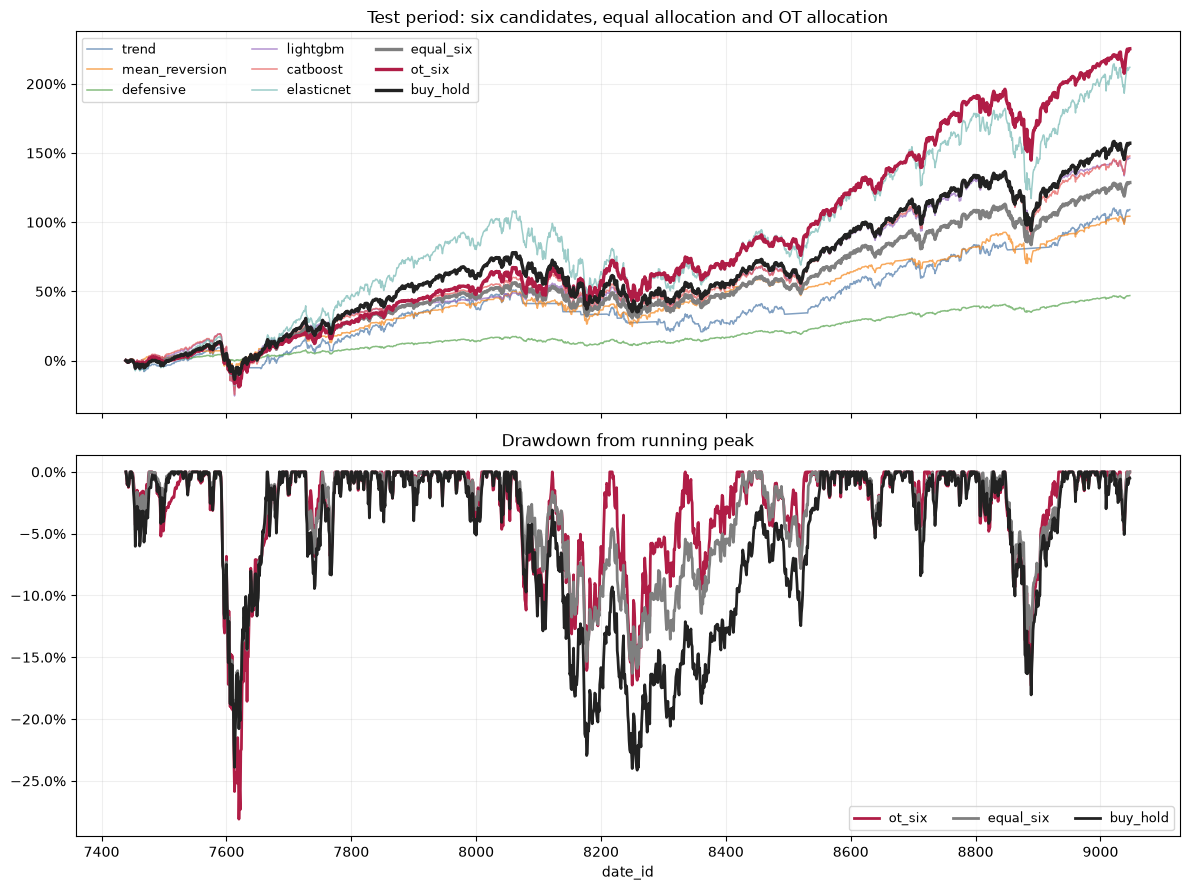

In [188]:
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter

# 所有账户的净值均从1开始；回撤包含初始净值1作为峰值。
test_nav = (1 + test_net_return).cumprod()
test_drawdown = test_nav / test_nav.cummax().clip(lower=1.0) - 1
test_colors = {
    "trend": "#4c78a8", "mean_reversion": "#f58518", "defensive": "#54a24b",
    "lightgbm": "#9467bd", "catboost": "#e45756", "elasticnet": "#72b7b2",
    "equal_six": "#7f7f7f", "ot_six": "#b01d46", "buy_hold": "#222222",
}
fig, axes = plt.subplots(2, 1, figsize=(12, 9), sharex=True)
for name in test_nav.columns:
    important = name in ["ot_six", "equal_six", "buy_hold"]
    axes[0].plot(test_nav.index, test_nav[name] - 1, label=name,
                 color=test_colors[name], lw=2.4 if important else 1.1,
                 alpha=1.0 if important else 0.7)
for name in ["ot_six", "equal_six", "buy_hold"]:
    axes[1].plot(test_drawdown.index, test_drawdown[name], label=name,
                 color=test_colors[name], lw=2)
axes[0].set_title("Test period: six candidates, equal allocation and OT allocation")
axes[1].set_title("Drawdown from running peak")
axes[1].set_xlabel("date_id")
for ax in axes:
    ax.yaxis.set_major_formatter(PercentFormatter(1))
    ax.grid(alpha=0.2)
    ax.legend(ncol=3, fontsize=9)
fig.tight_layout()
fig.savefig(TEST_RESULT_DIR / "test_curves.png", dpi=150)
plt.show()

从测试期结果来看，六策略OT把前面两节得到的配置优势进一步延伸到了样本外。1609个交易日内，组合累计净收益达到225.4%，年化收益为20.3%，Sharpe Ratio为0.910，三项指标都位居这组回测账户的首位。相比买入并持有的157.1%和六策略等权的128.7%，OT分别多获得68.3和96.7个百分点的累计净收益。这些结果已经计入现金收益、持仓漂移和单边1bp交易成本。

更有意思的是它与ElasticNet的比较。ElasticNet是测试期表现最好的单策略，累计收益达到211.9%，平均市场仓位为1.304倍。OT把累计收益进一步提高了13.5个百分点，同时将平均市场仓位降到0.935倍，低于买入并持有的1倍仓位。这和第四节的结果形成了很清楚的呼应：通过识别市场状态、调整策略之间的配置，我们用更低的平均市场暴露，取得了更高的累计收益。

两者的风险收益结构也发生了变化。相对于ElasticNet，OT将年化波动率从23.4%降到19.5%，最大回撤从−31.5%收缩到−28.1%，Sharpe从0.767提高到0.910。也就是说，组合在保留强策略收益机会的同时，改善了持有单一策略时的波动和回撤表现。相对于买入并持有，OT承担了更高的波动和回撤，对应更高的收益与Sharpe；这体现了当前配置方案的收益与风险取舍。

再看OT具体选择了什么。测试期内，ElasticNet的平均最终权重为36.60%，在60.29%的交易日获得配置，是六种策略中占比最高的一种；LightGBM与CatBoost合计占29.78%，三条基础策略合计占33.62%。这组权重与测试期ElasticNet较强的单策略表现相吻合，同时也保留了树模型、趋势、均值回归和低仓位防守策略的配置空间。不同结构的策略因此能够在同一套市场状态检索框架下参与竞争和组合。

平均权重之外，每天的选择同样有特点。在1609个测试日中：
- 248日只选择一个策略；
- 942日选择两个策略；
- 419日选择三个策略。

六个候选策略中，每天实际入选的最多只有三个。OT先找到与当前市场相似的历史窗口，再根据这些时期后续的策略表现缩小选择范围，将资金集中到当日评分更高的策略上。从第三节的基础策略，到第四节的三模型组合，再到这里的六策略配置，这套方法始终保留了相同的逻辑：让市场状态决定策略配置。

至此，我们把整个项目连成了一条完整的路径：用滚动特征描述市场状态，用Wasserstein距离寻找历史近邻，用OOF策略收益建立可供检索的历史表现，再把近邻信息转换成当天的策略权重和市场仓位。第五节给出的核心结果是，这个配置层在固定参数的测试期回测中，同时超过了六策略等权和最佳单策略的累计收益，并取得最高的Sharpe。市场状态相似性由此成为可以落实到实际仓位、并通过回测检验的配置依据。